# Research Question
Can historical customer ratings and book characteristics help predict which books a customer is likely to rate positively, supporting more personalized recommendations?

In [3]:
import json

# Inspect original dataset structures
files = {
    "Reviews": "Books.jsonl",
    "Metadata": "meta_Books.jsonl"
}

for name, filename in files.items():
    with open(filename, "r", encoding="utf-8") as file:
        record = json.loads(file.readline())

    print(f"\n{name} Dataset")
    print("Columns:", list(record.keys()))
    print("Joining key:", record.get("parent_asin"))


Reviews Dataset
Columns: ['rating', 'title', 'text', 'images', 'asin', 'parent_asin', 'user_id', 'timestamp', 'helpful_vote', 'verified_purchase']
Joining key: B09BGPFTDB

Metadata Dataset
Columns: ['main_category', 'title', 'subtitle', 'author', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together']
Joining key: 0701169850


### Initial Dataset Structure and Interpretation

The initial inspection confirmed that both the customer reviews and book metadata datasets contain `parent_asin`, providing a candidate joining key for combining customer interactions with book characteristics. Both datasets also contain overlapping columns, including `title` and `images`, which will need to be distinguished during the merge.

The book identifiers should be preserved as strings because some contain leading zeros, which could be lost through numeric conversion. Although the initial records have different identifiers, this is expected because the files are not necessarily organized in corresponding order.

Before merging, additional checks are needed to assess missing values, duplicate identifiers, and the uniqueness of metadata records to ensure the join does not introduce unintended duplication.

In [4]:
import pandas as pd

# Load the first 10,000 rows from each dataset
books_reviews = next(pd.read_json(
    "Books.jsonl",
    lines=True,
    chunksize=10000
))

books_metadata = next(pd.read_json(
    "meta_Books.jsonl",
    lines=True,
    chunksize=10000
))

# Inspect data quality in each sample
for name, df in [
    ("Reviews", books_reviews),
    ("Metadata", books_metadata)
]:
    print(f"\n{name} Dataset")
    print("Shape:", df.shape)

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nMissing book identifiers:")
    print(df["parent_asin"].isnull().sum())

    print("\nDuplicate book identifiers:")
    print(df["parent_asin"].duplicated().sum())


Reviews Dataset
Shape: (10000, 10)

Data types:
rating                        int64
title                           str
text                            str
images                       object
asin                            str
parent_asin                     str
user_id                         str
timestamp            datetime64[ms]
helpful_vote                  int64
verified_purchase              bool
dtype: object

Missing values:
rating               0
title                0
text                 0
images               0
asin                 0
parent_asin          0
user_id              0
timestamp            0
helpful_vote         0
verified_purchase    0
dtype: int64

Missing book identifiers:
0

Duplicate book identifiers:
449

Metadata Dataset
Shape: (10000, 16)

Data types:
main_category          str
title                  str
subtitle               str
author              object
average_rating     float64
rating_number        int64
features            object
description     

### Initial Data Quality Assessment

The initial assessment examined 10,000 observations from each dataset. The reviews sample contains no detected missing values, while the metadata sample has missing values in several fields, particularly author (28.18%) and price (6.72%). Neither sample contains missing book identifiers.

The reviews sample contains 449 repeated `parent_asin` identifiers, which is expected because multiple customers may review the same book. The metadata sample contains no repeated book identifiers, supporting a potential many-to-one relationship between reviews and book information.

These findings are preliminary because only the first 10,000 observations from each dataset were examined. Further checks are necessary to identify actual duplicate records, evaluate missing information, and validate the merge before proceeding with the full EDA.

In [5]:
# Check for potentially repeated review events
duplicate_reviews = books_reviews.duplicated(
    subset=["user_id", "asin", "timestamp", "rating", "text"]
).sum()

print("Potential duplicate review events:", duplicate_reviews)

Potential duplicate review events: 0


### Duplicate Review Assessment

The duplicate review assessment identified zero repeated review events among the first 10,000 observations based on customer ID, product ID, timestamp, rating, and review text. This supports the interpretation that the previously identified repeated book identifiers represent separate customer review interactions rather than duplicated review events.

No duplicate removal is necessary based on this preliminary check. However, the findings are limited to the initial sample and do not establish that the full dataset is free of duplicates.

In [6]:
# Compare book identifiers across both samples
review_ids = set(books_reviews["parent_asin"])
metadata_ids = set(books_metadata["parent_asin"])

shared_ids = review_ids.intersection(metadata_ids)

print("Shared book identifiers:", len(shared_ids))

print(
    "Review rows with matching metadata:",
    books_reviews["parent_asin"].isin(metadata_ids).sum()
)

Shared book identifiers: 28
Review rows with matching metadata: 30


### Preliminary Dataset Matching Assessment

The comparison identified 28 unique book identifiers shared between the initial review and metadata samples, corresponding to 30 customer review observations. This suggests a many-to-one relationship in which multiple customer reviews can be associated with a single book record.

Only 0.3% of sampled review observations matched the initial metadata sample. However, this low match rate cannot be interpreted as the overall dataset's matching rate because both samples represent small portions of substantially larger files.

These results confirm that the datasets contain overlapping identifiers but indicate that a broader metadata lookup will be necessary to construct a sufficiently complete analytical dataset.

In [7]:
# Select reviews with matching metadata
matched_reviews = books_reviews[
    books_reviews["parent_asin"].isin(shared_ids)
].copy()

# Select relevant metadata columns
metadata_subset = books_metadata[
    ["parent_asin", "title", "author", "price", "categories"]
].rename(columns={"title": "book_title"})

# Test the many-to-one merge
test_merge = matched_reviews.merge(
    metadata_subset,
    on="parent_asin",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Reviews before merge:", len(matched_reviews))
print("Rows after merge:", len(test_merge))
print("\nMerge results:")
print(test_merge["_merge"].value_counts())

test_merge[
    ["parent_asin", "user_id", "rating",
     "book_title", "author", "price"]
].head()

Reviews before merge: 30
Rows after merge: 30

Merge results:
_merge
both          30
left_only      0
right_only     0
Name: count, dtype: int64


,parent_asin,user_id,rating,book_title,author,price
0,0394800184,AFZUK3MTBIBEDQOPAK3OATUOUKLA,5,Are You My Mother ?,{'avatar': 'https://m.media-amazon.com/images/...,5.29
1,1119687799,AFFZVSTUS3U2ZD22A2NPZSKOCPGQ,4,iPhone Photography For Dummies,{'avatar': 'https://m.media-amazon.com/images/...,17.89
2,0732297818,AFW2PDT3AMT4X3PYQG7FJZH5FXFA,5,The Feast Goes On,{'avatar': 'https://m.media-amazon.com/images/...,35.00
3,1949467163,AHV6QCNBJNSGLATP56JAWJ3C4G2A,3,The Baddest Girl on the Planet,{'avatar': 'https://m.media-amazon.com/images/...,15.00
4,1483836088,AHV6QCNBJNSGLATP56JAWJ3C4G2A,5,"Ready to Go Guided Reading: Summarize, Grades ...",{'avatar': 'https://m.media-amazon.com/images/...,19.79


### Preliminary Merge Validation

The test merge successfully combined all 30 selected customer reviews with their corresponding book metadata using `parent_asin`. The number of observations remained unchanged, and all 30 records were classified as matched. The many-to-one validation also passed, indicating no unintended duplication of review observations.

These findings support the selected joining strategy. However, because the test included only previously matched records, it does not establish the matching rate across the complete datasets. The merged output also revealed that certain fields, particularly author information, may contain nested structures requiring further inspection.

The next step is to expand the metadata matching process while preserving review observations and evaluating the completeness of the resulting dataset.

In [8]:
# Find metadata for all 10,000 sampled reviews
review_ids = set(
    books_reviews["parent_asin"].astype("string").dropna()
)

metadata_matches = []

for chunk in pd.read_json(
    "meta_Books.jsonl",
    lines=True,
    chunksize=5000,
    dtype={"parent_asin": "string"}
):
    matching = chunk.loc[
        chunk["parent_asin"].isin(review_ids),
        ["parent_asin", "title", "author", "price", "categories"]
    ]

    if not matching.empty:
        metadata_matches.append(matching)

# Combine only the matching metadata records
full_metadata_matches = pd.concat(
    metadata_matches,
    ignore_index=True
)

print("Matching metadata records:", len(full_metadata_matches))

print(
    "Duplicate metadata identifiers:",
    full_metadata_matches["parent_asin"].duplicated().sum()
)

Matching metadata records: 9551
Duplicate metadata identifiers: 0


### Expanded Metadata Matching Assessment

The expanded metadata search identified 9,551 matching book records, with no duplicate `parent_asin` identifiers. This matches the number of unique book identifiers in the initial 10,000-review sample, suggesting complete metadata coverage for the sampled reviews.

The results also support a many-to-one joining relationship, where multiple customer reviews may correspond to a single book. A final merge validation is required to confirm that all review observations are retained without unintended duplication.

Although the metadata search covered the complete metadata file, these findings only establish coverage for the initial review sample, not the full reviews dataset.

In [9]:
# Prepare review and metadata datasets
review_sample = books_reviews.copy()
metadata_for_join = full_metadata_matches.copy()

# Preserve book identifiers as strings
review_sample["parent_asin"] = (
    review_sample["parent_asin"].astype("string")
)

metadata_for_join["parent_asin"] = (
    metadata_for_join["parent_asin"].astype("string")
)

# Distinguish review titles from book titles
review_sample = review_sample.rename(
    columns={"title": "review_title"}
)

metadata_for_join = metadata_for_join.rename(
    columns={"title": "book_title"}
)

# Merge reviews with matching book metadata
books_combined = review_sample.merge(
    metadata_for_join,
    on="parent_asin",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Validate the merge
print("Original reviews:", len(review_sample))
print("Combined rows:", len(books_combined))

print("\nMerge results:")
print(books_combined["_merge"].value_counts())

books_combined[
    [
        "parent_asin",
        "user_id",
        "rating",
        "book_title",
        "price"
    ]
].head()

Original reviews: 10000
Combined rows: 10000

Merge results:
_merge
both          10000
left_only         0
right_only        0
Name: count, dtype: int64


,parent_asin,user_id,rating,book_title,price
0,B09BGPFTDB,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,1,Watercolor with Me in the Ocean: Coloring book...,5.99
1,0593235657,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,5,Get Untamed: The Journal (How to Quit Pleasing...,10.49
2,1782490671,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,5,Cute & Easy Crochet with Flowers: 35 beautiful...,21.95
3,0593138228,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,5,The Pop Manga Sketchbook: A Guided Drawing Jou...,None
4,0823098079,AFKZENTNBQ7A7V7UXW5JJI6UGRYQ,5,Haiku Knits: 25 Serenely Beautiful Patterns In...,19.61


### Expanded Merge Validation

The expanded merge successfully combined all 10,000 sampled customer reviews with their corresponding book metadata using `parent_asin`. All observations were matched, and the resulting dataset retained the original number of review records, confirming that the join did not introduce unintended duplication or observation loss.

The combined dataset now incorporates customer ratings and identifiers alongside book characteristics, including titles, authors, prices, and categories. However, some metadata fields contain missing values that will require further evaluation.

Although the merge achieved complete coverage for the initial sample, this does not establish the matching rate for the full Amazon Books dataset.

In [10]:
# Assess the composition of the merged sample
print("Dataset shape:", books_combined.shape)

print(
    "Unique customers:",
    books_combined["user_id"].nunique()
)

print(
    "Unique books:",
    books_combined["parent_asin"].nunique()
)

# Examine review concentration
print("\nReviews per customer:")
print(books_combined["user_id"].value_counts().head(10))

# Check missing book characteristics
print("\nMissing metadata values:")
print(
    books_combined[
        ["book_title", "author", "price", "categories"]
    ].isna().sum()
)

# Examine the time period covered
print("\nReview date range:")
print(books_combined["timestamp"].min())
print(books_combined["timestamp"].max())

Dataset shape: (10000, 15)
Unique customers: 578
Unique books: 9551

Reviews per customer:
user_id
AFWVN52MRBWOTIK7UGXBWGOY4HBA    2681
AEYGPUCRKH7G4VM22FM3VAKSQ23Q     752
AGLQQCIS5V6EGUCS5SSNHWZHQM6Q     597
AFLX66DKF6R3H6OEOC3TIVAYXZIQ     507
AFW2PDT3AMT4X3PYQG7FJZH5FXFA     416
AEICZD35OTDYVWA2KPYWN4PDZ2SA     408
AFXF3EGQTQDXMRLDWFU7UBFQZB7Q     305
AHV6QCNBJNSGLATP56JAWJ3C4G2A     296
AHPFHP43AXWRYZZ4HPNCW7I7J3ZQ     203
AFQ7WYW4KSH4VI5OVXCP2GV6PBRA     157
Name: count, dtype: int64

Missing metadata values:
book_title       0
author        1505
price         1188
categories       0
dtype: int64

Review date range:
1998-05-05 22:56:55
2023-03-16 19:30:58.903000


### Sample Composition and Representativeness

The initial merged dataset contains 10,000 reviews from 578 unique customers across 9,551 books. Review activity is highly concentrated, with the most active customer contributing 26.81% of observations and the ten most active customers accounting for 63.22%.

This concentration suggests that the first 10,000 records may not provide a representative view of the broader customer population. The sample also contains missing author information (15.05%) and prices (11.88%), while review timestamps span 1998 to 2023.

Although the merge was successful, the initial sample is more appropriate for validating data structure and integration than for drawing conclusions about overall customer preferences. A more systematic sampling strategy is needed before conducting the final EDA and predictive modeling.

In [11]:
import json
import gzip
import hashlib

# Sampling parameters
sample_rate = 0.005
seed = "ADS505-2026"
threshold = int(sample_rate * 2**64)

# Select customers consistently using their IDs
def select_customer(user_id):
    if not isinstance(user_id, str) or not user_id:
        return False

    hashed_id = hashlib.blake2b(
        f"{seed}|{user_id}".encode("utf-8"),
        digest_size=8
    ).digest()

    return int.from_bytes(hashed_id, "big") < threshold


# Stream through the complete reviews dataset
total_reviews = 0
sampled_reviews = 0

with open("Books.jsonl", "r", encoding="utf-8") as source:
    with gzip.open(
        "books_reviews_customer_sample.jsonl.gz",
        "wt",
        encoding="utf-8"
    ) as destination:

        for line in source:
            total_reviews += 1
            review = json.loads(line)

            if select_customer(review.get("user_id")):
                destination.write(line)
                sampled_reviews += 1

            # Report progress every million reviews
            if total_reviews % 1_000_000 == 0:
                print(
                    f"Processed: {total_reviews:,} | "
                    f"Selected: {sampled_reviews:,}",
                    flush=True
                )

print("\nSampling complete!")
print("Total reviews processed:", total_reviews)
print("Sampled reviews:", sampled_reviews)

Processed: 1,000,000 | Selected: 4,082
Processed: 2,000,000 | Selected: 8,614
Processed: 3,000,000 | Selected: 13,837
Processed: 4,000,000 | Selected: 19,235
Processed: 5,000,000 | Selected: 25,757
Processed: 6,000,000 | Selected: 30,304
Processed: 7,000,000 | Selected: 34,974
Processed: 8,000,000 | Selected: 41,477
Processed: 9,000,000 | Selected: 48,110
Processed: 10,000,000 | Selected: 53,360
Processed: 11,000,000 | Selected: 58,701
Processed: 12,000,000 | Selected: 63,651
Processed: 13,000,000 | Selected: 69,084
Processed: 14,000,000 | Selected: 74,162
Processed: 15,000,000 | Selected: 78,816
Processed: 16,000,000 | Selected: 83,632
Processed: 17,000,000 | Selected: 88,518
Processed: 18,000,000 | Selected: 93,933
Processed: 19,000,000 | Selected: 99,707
Processed: 20,000,000 | Selected: 104,142
Processed: 21,000,000 | Selected: 108,588
Processed: 22,000,000 | Selected: 113,599
Processed: 23,000,000 | Selected: 118,507
Processed: 24,000,000 | Selected: 123,539
Processed: 25,000,000 

### Customer-Based Sampling Assessment

To address the customer concentration observed in the initial 10,000-row sample, a reproducible customer-based sampling procedure was applied across the complete Books reviews dataset.

The procedure processed 29,475,453 reviews and selected 151,062 observations, representing approximately 0.51% of all reviews. Customers were selected using a fixed-seed hashing method, with all reviews belonging to selected customers retained.

This approach avoids relying on the ordering of the original dataset and preserves customer interaction histories. However, additional checks are necessary to evaluate reviewer concentration, rating distributions, and whether the sample provides sufficient information for personalized recommendation modeling.

In [12]:
# Load the sampled reviews
books_sample = pd.read_json(
    "books_reviews_customer_sample.jsonl.gz",
    lines=True,
    compression="gzip",
    dtype={
        "user_id": "string",
        "parent_asin": "string",
        "asin": "string"
    }
)

# Basic sample composition
print("Sample shape:", books_sample.shape)
print("Unique customers:", books_sample["user_id"].nunique())
print("Unique books:", books_sample["parent_asin"].nunique())

# Customer review frequency
customer_counts = books_sample["user_id"].value_counts()

print("\nReviews per customer:")
print(customer_counts.describe())

print("\nCustomers with at least 5 reviews:")
print((customer_counts >= 5).sum())

print("\nTop 10 customers' share of reviews:")
print(
    round(customer_counts.head(10).sum() / len(books_sample) * 100, 2),
    "%"
)

# Rating distribution
print("\nRating distribution:")
print(books_sample["rating"].value_counts().sort_index())

Sample shape: (151062, 10)
Unique customers: 51645
Unique books: 118648

Reviews per customer:
count     51645.0
mean     2.925007
std      13.69783
min           1.0
25%           1.0
50%           1.0
75%           2.0
max        1844.0
Name: count, dtype: Float64

Customers with at least 5 reviews:
6093

Top 10 customers' share of reviews:
4.78 %

Rating distribution:
rating
1      6610
2      5253
3     10284
4     24175
5    104740
Name: count, dtype: int64


### Customer Sampling and Rating Distribution Assessment

The revised sample contains 151,062 reviews from 51,645 customers across 118,648 books. The top ten customers account for 4.78% of observations, substantially reducing the concentration observed in the initial sample.

However, customer interaction histories remain sparse. The median customer has only one review, and 6,093 customers have at least five reviews. This may limit the information available for personalized predictions and warrants further consideration during modeling.

The rating distribution is also strongly skewed toward positive evaluations, with approximately 69.3% of reviews receiving five stars and 85.3% receiving four or five stars. This suggests that potential classification models will need to account for class imbalance and should not be evaluated using accuracy alone.

In [13]:
import json
import pandas as pd

# Identify books in the new review sample
sample_book_ids = set(
    books_sample["parent_asin"].dropna().astype(str)
)

matching_metadata = []

# Search the complete metadata file
with open("meta_Books.jsonl", "r", encoding="utf-8") as source:
    for line_number, line in enumerate(source, start=1):
        record = json.loads(line)
        book_id = record.get("parent_asin")

        if book_id in sample_book_ids:
            matching_metadata.append({
                "parent_asin": book_id,
                "book_title": record.get("title"),
                "main_category": record.get("main_category"),
                "categories": record.get("categories"),
                "price": record.get("price")
            })

        if line_number % 1_000_000 == 0:
            print(f"Metadata records scanned: {line_number:,}")

# Create the matching metadata DataFrame
book_metadata_sample = pd.DataFrame(matching_metadata)

print("\nMetadata records found:", len(book_metadata_sample))

print(
    "Unique books matched:",
    book_metadata_sample["parent_asin"].nunique()
)

print(
    "Duplicate metadata identifiers:",
    book_metadata_sample["parent_asin"].duplicated().sum()
)

print(
    "Unmatched book identifiers:",
    len(sample_book_ids -
        set(book_metadata_sample["parent_asin"]))
)

Metadata records scanned: 1,000,000
Metadata records scanned: 2,000,000
Metadata records scanned: 3,000,000
Metadata records scanned: 4,000,000

Metadata records found: 118648
Unique books matched: 118648
Duplicate metadata identifiers: 0
Unmatched book identifiers: 0


### Metadata Matching Assessment

The metadata search identified 118,648 matching book records, corresponding to all 118,648 unique book identifiers in the revised review sample. No duplicate metadata identifiers or unmatched book identifiers were found, indicating complete metadata coverage for the selected sample.

These findings support the use of a many-to-one merge, preserving individual customer reviews while adding the associated book characteristics. The next step is to validate that the combined dataset retains all 151,062 review observations without unintended duplication or observation loss.

In [14]:
# Prepare datasets for the final sample merge
reviews_for_merge = books_sample.copy()
metadata_for_merge = book_metadata_sample.copy()

# Preserve book identifiers as strings
reviews_for_merge["parent_asin"] = (
    reviews_for_merge["parent_asin"].astype("string")
)

metadata_for_merge["parent_asin"] = (
    metadata_for_merge["parent_asin"].astype("string")
)

# Distinguish customer review titles from book titles
reviews_for_merge = reviews_for_merge.rename(
    columns={"title": "review_title"}
)

# Combine customer reviews with book information
books_combined_final = reviews_for_merge.merge(
    metadata_for_merge,
    on="parent_asin",
    how="left",
    validate="many_to_one",
    indicator=True
)

# Validate the final merge
print("Original reviews:", len(reviews_for_merge))
print("Combined rows:", len(books_combined_final))

print("\nMerge results:")
print(books_combined_final["_merge"].value_counts())

print("\nCombined dataset shape:")
print(books_combined_final.shape)

# Preview the combined observations
books_combined_final[
    [
        "parent_asin",
        "user_id",
        "rating",
        "book_title",
        "main_category",
        "price"
    ]
].head()

Original reviews: 151062
Combined rows: 151062

Merge results:
_merge
both          151062
left_only          0
right_only         0
Name: count, dtype: int64

Combined dataset shape:
(151062, 15)


,parent_asin,user_id,rating,book_title,main_category,price
0,1493016865,AEO4M665ZOCBF7HEFRMTUDHLSB5Q,5,Best Easy Day Hikes Shenandoah National Park (...,Books,None
1,0525952926,AEHJJPC3MQJAHAJWBEVIF5EFQQBQ,5,Winter of the World: Book Two of the Century T...,Books,4.25
2,1684511801,AHYEA4JYQ6G2PVYXDUN7S5RPXJFQ,5,Fault Lines: The Social Justice Movement and E...,Books,None
3,0060559713,AG45KIZNC57OEUXIZFDNZWIMTUNA,5,The Day the World Came to Town: 9/11 in Gander...,Books,16.98
4,0147508770,AG45KIZNC57OEUXIZFDNZWIMTUNA,5,The Longmire Mystery Series Boxed Set Volumes ...,Books,33.96


### Final Analytical Dataset Integration

The final merge successfully combined 151,062 customer reviews with their corresponding book metadata using `parent_asin`. All review observations matched, and the resulting dataset contains 151,062 rows and 15 columns. The unchanged row count confirms that the merge did not introduce unintended duplication or observation loss.

The combined dataset provides a foundation for examining customer ratings alongside book characteristics, including titles, categories, and prices. However, the initial preview reveals missing price information, indicating that further data-quality assessment is necessary before proceeding with exploratory analysis.

The complete matching rate applies to the selected sample and should not be generalized to the entire Amazon Books dataset.

In [15]:
# Inspect combined dataset structure
books_combined_final.info()

# Missing-value summary
missing_summary = pd.DataFrame({
    "Missing Count": books_combined_final.isna().sum(),
    "Missing %": (
        books_combined_final.isna().mean() * 100
    ).round(2)
})

print("\nMissing Values:")
display(
    missing_summary.sort_values(
        "Missing Count",
        ascending=False
    )
)

# Check for empty book categories
empty_categories = books_combined_final["categories"].apply(
    lambda x: isinstance(x, list) and len(x) == 0
).sum()

print("\nEmpty category lists:", empty_categories)

# Check for potentially duplicated review events
duplicate_reviews = books_combined_final.duplicated(
    subset=[
        "user_id", "asin", "timestamp",
        "rating", "text"
    ]
).sum()

print("Potential duplicate review events:", duplicate_reviews)

<class 'pandas.DataFrame'>
RangeIndex: 151062 entries, 0 to 151061
Data columns (total 15 columns):
 #   Column             Non-Null Count   Dtype         
---  ------             --------------   -----         
 0   rating             151062 non-null  int64         
 1   review_title       151062 non-null  str           
 2   text               151062 non-null  str           
 3   images             151062 non-null  object        
 4   asin               151062 non-null  string        
 5   parent_asin        151062 non-null  string        
 6   user_id            151062 non-null  string        
 7   timestamp          151062 non-null  datetime64[ms]
 8   helpful_vote       151062 non-null  int64         
 9   verified_purchase  151062 non-null  bool          
 10  book_title         151062 non-null  str           
 11  main_category      151052 non-null  str           
 12  categories         151062 non-null  object        
 13  price              133542 non-null  object        
 14 

,Missing Count,Missing %
price,17520,11.60
main_category,10,0.01
rating,0,0.00
images,0,0.00
asin,0,0.00
review_title,0,0.00
text,0,0.00
user_id,0,0.00
parent_asin,0,0.00
timestamp,0,0.00



Empty category lists: 5894
Potential duplicate review events: 2012


### Combined Dataset Data Quality Assessment

The merged dataset contains 151,062 observations and 15 variables. All customer identifiers, book identifiers, ratings, timestamps, and book titles are present, indicating that the primary variables needed for the analysis are complete.

Missing information is concentrated in the book metadata. Price is missing for 17,520 observations (11.60%), while main category is missing for only 10 observations. Additionally, 5,894 observations (3.90%) contain empty category lists, demonstrating that conventional null-value checks do not capture all forms of incomplete information.

The duplicate-event assessment also identified 2,012 potentially repeated review records (1.33%) based on selected review attributes. These observations require further examination before determining whether removal is appropriate.

Overall, the dataset is suitable for continued exploratory analysis, although missing metadata, variable formatting, and possible duplicate review events warrant additional investigation before modeling.

In [16]:
# Identify all rows belonging to repeated review groups
review_keys = [
    "user_id", "asin", "timestamp", "rating", "text"
]

duplicate_mask = books_combined_final.duplicated(
    subset=review_keys,
    keep=False
)

duplicate_candidates = books_combined_final.loc[
    duplicate_mask
].copy()

# Assign a group number to each repeated review event
duplicate_candidates["group_id"] = (
    duplicate_candidates.groupby(
        review_keys,
        dropna=False
    ).ngroup()
)

print("Rows in repeated groups:", len(duplicate_candidates))
print("Repeated review groups:",
      duplicate_candidates["group_id"].nunique())

# Compare potentially duplicated records
display(
    duplicate_candidates[
        [
            "group_id",
            "user_id",
            "asin",
            "parent_asin",
            "rating",
            "review_title",
            "helpful_vote",
            "verified_purchase"
        ]
    ].sort_values("group_id").head(12)
)

Rows in repeated groups: 3691
Repeated review groups: 1679


,group_id,user_id,asin,parent_asin,rating,review_title,helpful_vote,verified_purchase
143860,0,AE2AYX7FW4AN2OFDOPKT46XGXT3Q,0620655577,0620655577,5,Masterpiece!,3,False
143858,0,AE2AYX7FW4AN2OFDOPKT46XGXT3Q,0620655577,0620655577,5,Masterpiece!,3,False
143857,1,AE2AYX7FW4AN2OFDOPKT46XGXT3Q,B07199HKY5,B07199HKY5,5,An incredible second book in the series.,1,False
143859,1,AE2AYX7FW4AN2OFDOPKT46XGXT3Q,B07199HKY5,B07199HKY5,5,An incredible second book in the series.,1,False
120901,2,AE2DNWTW5GTLWIJGRD4HZA6SM6KQ,0520271564,0520271564,5,Five Stars,0,True
120900,2,AE2DNWTW5GTLWIJGRD4HZA6SM6KQ,0520271564,0520271564,5,Five Stars,0,True
120898,2,AE2DNWTW5GTLWIJGRD4HZA6SM6KQ,0520271564,0520271564,5,Five Stars,0,True
120899,2,AE2DNWTW5GTLWIJGRD4HZA6SM6KQ,0520271564,0520271564,5,Five Stars,0,True
120902,2,AE2DNWTW5GTLWIJGRD4HZA6SM6KQ,0520271564,0520271564,5,Five Stars,0,True
130811,3,AE2RGXOBTONHQ6QGSR73WOLDPGPQ,0061996556,0061996556,5,We love Charlie!,7,False


### Investigation of Potential Duplicate Reviews

The duplicate assessment identified 3,691 observations belonging to 1,679 repeated review groups, corresponding to 2,012 additional occurrences beyond the first observation in each group.

An inspection of the repeated groups showed that several records share identical customer identifiers, product identifiers, ratings, review titles, helpful-vote counts, and verified-purchase indicators. This suggests that some observations may represent duplicated review events rather than independent customer interactions.

Before removing these observations, the remaining review attributes should be compared to confirm whether the records are genuinely identical. Retaining duplicated reviews could disproportionately influence descriptive statistics and predictive modeling results.

In [17]:
import json

# Original review fields, excluding book metadata
review_columns = [
    "rating",
    "review_title",
    "text",
    "images",
    "asin",
    "parent_asin",
    "user_id",
    "timestamp",
    "helpful_vote",
    "verified_purchase"
]

review_records = books_combined_final[review_columns].copy()

# Convert nested image data into comparable strings
review_records["images"] = review_records["images"].apply(
    lambda x: json.dumps(x, sort_keys=True, default=str)
)

# Compare complete review records
exact_duplicates = review_records.duplicated().sum()

print("Exact duplicate review records:", exact_duplicates)

print(
    "Potential duplicates differing in other fields:",
    2012 - exact_duplicates
)

Exact duplicate review records: 2012
Potential duplicates differing in other fields: 0


### Duplicate Review Validation and Cleaning Decision

The full-record duplicate assessment confirmed 2,012 exact duplicate observations, with no differences across the original review attributes. This verifies that the repeated records identified earlier are identical review events rather than separate observations.

Based on this finding, the 2,012 additional copies will be removed while preserving one occurrence of each review. This prevents duplicated observations from disproportionately influencing descriptive statistics and predictive modeling. The original merged dataset will remain unchanged for reproducibility.

In [18]:
# Identify exact duplicates from the complete review comparison
exact_duplicate_mask = review_records.duplicated(
    keep="first"
)

# Remove duplicates while preserving the original dataset
books_clean = books_combined_final.loc[
    ~exact_duplicate_mask
].copy()

# Remove the merge-validation indicator
books_clean = books_clean.drop(columns=["_merge"])

# Reset the index
books_clean = books_clean.reset_index(drop=True)

# Verify cleaning results
print("Original rows:", len(books_combined_final))
print("Duplicates removed:", exact_duplicate_mask.sum())
print("Cleaned rows:", len(books_clean))

print("\nCleaned dataset shape:", books_clean.shape)

Original rows: 151062
Duplicates removed: 2012
Cleaned rows: 149050

Cleaned dataset shape: (149050, 14)


In [19]:
# Examine price values after duplicate removal
price_text = books_clean["price"].astype("string").str.strip()

# Convert prices to numeric values for inspection
price_numeric = pd.to_numeric(
    price_text,
    errors="coerce"
)

# Identify missing and invalid prices
missing_prices = books_clean["price"].isna().sum()

invalid_prices = (
    price_text.notna() & price_numeric.isna()
).sum()

print("Missing prices:", missing_prices)

print(
    "Missing price percentage:",
    round(missing_prices / len(books_clean) * 100, 2),
    "%"
)

print("Non-numeric prices:", invalid_prices)

print(
    "Zero or negative prices:",
    (price_numeric <= 0).sum()
)

# Summary statistics for valid numeric prices
print("\nPrice summary:")
display(price_numeric.describe())

# Inspect any values that could not be converted
print("\nExamples of non-numeric prices:")
display(
    books_clean.loc[
        price_text.notna() & price_numeric.isna(),
        ["book_title", "price"]
    ].head(10)
)

Missing prices: 17281
Missing price percentage: 11.59 %
Non-numeric prices: 5465
Zero or negative prices: 9641

Price summary:


count     126304.0
mean     17.623072
std      50.871351
min            0.0
25%           7.99
50%          12.35
75%          18.05
max        9653.81
Name: price, dtype: Float64


Examples of non-numeric prices:


,book_title,price
7,Tropical Butterflies Stained Glass Coloring Bo...,—
9,"Boxer Dogs,Boxers, My Life with Boxers",from 19.99
38,Right Wing Women,—
44,Street & Smith's 2019-2020 College Basketball ...,—
53,Fallout 4 Ultimate Vault Dweller's Survival Gu...,from 199.95
96,Hummingbirds Wall Calendar (2018),—
107,Siberian Husky Puppies 2013 Square 12X12,—
113,Rocky Men's Micks Gym Training T-Shirt Black M,—
163,The Organic Kitchen Garden 2018 Wall Calendar:...,—
166,The Organic Kitchen Garden 2016 Wall Calendar,—


### Price Data Quality Assessment

The price assessment identified 17,281 missing observations (11.59%) and an additional 5,465 non-numeric entries. Non-numeric values include unavailable-price indicators and starting-price descriptions, which cannot automatically be interpreted as exact selling prices.

The dataset also contains 9,641 nonpositive numeric prices, with a minimum recorded value of zero. The price distribution appears right-skewed, with a mean of USD 17.62, median of USD 12.35, and maximum of USD 9,653.81.

These findings indicate that price requires additional validation before it can be used reliably in exploratory analysis or predictive modeling. Customer review observations will be retained while invalid, unavailable, and unusually high price values are investigated separately.

In [20]:
# Reconstruct price values without modifying the dataset
raw_price = books_clean["price"].astype("string").str.strip()

numeric_price = pd.to_numeric(
    raw_price,
    errors="coerce"
)

# Separate zero and negative prices
print("Zero prices:", (numeric_price == 0).sum())
print("Negative prices:", (numeric_price < 0).sum())

# Examine non-numeric price formats
invalid_mask = raw_price.notna() & numeric_price.isna()

print("\nMost common non-numeric price values:")
display(
    raw_price[invalid_mask].value_counts().head(15)
)

# Examine unusually high prices
print("\nTen highest recorded prices:")
price_inspection = books_clean.assign(
    numeric_price=numeric_price
)

display(
    price_inspection[
        ["book_title", "numeric_price"]
    ].nlargest(10, "numeric_price")
)

Zero prices: 9641
Negative prices: 0

Most common non-numeric price values:


price
—             2733
from 4.95       47
from 19.99      33
from 20.00      28
from 25.00      24
from 29.99      23
from 10.00      21
from 0.99       20
from 12.00      19
from 39.99      18
from 14.99      18
from 1.35       17
from 15.00      17
from 9.99       17
from 24.99      16
Name: count, dtype: Int64


Ten highest recorded prices:


,book_title,numeric_price
46283,"The Adventures of Hamtaro, Vol. 3: Jealous Ham...",9653.81
23444,The Whole Truth About Fatima: Science and the ...,6092.81
35488,A B to Jay-Z,3890.0
46048,Country Living Cottage Style,3500.0
53316,Day of the Dead Folk Art,2516.0
142691,Three Trees Make a Forest,2342.51
134788,My Body is a Rainbow: A Book About Our Chakras,2176.74
17066,The EC Archives: The Haunt of Fear Volume 3 (E...,1599.97
39196,Anguish languish,1599.97
75237,Aphrodite IX: The Complete Series,1599.97


### Price Format and Outlier Assessment

Further investigation confirmed 9,641 zero-price observations and no negative numeric prices. Non-numeric values include unavailable-price indicators, such as an em-dash, and starting-price descriptions such as "from 19.99." These formats cannot reliably be interpreted as exact book prices.

The dataset also contains unusually high prices, including observations exceeding USD 6,000 and USD 9,000. Although these values may reflect unusual listings or data-quality issues, there is insufficient evidence to classify them as errors.

For subsequent analysis, the original price values will be preserved, while a separate numeric variable will be created. Unavailable or ambiguous prices will remain missing rather than being automatically imputed, and zero and unusually high prices will be flagged for further examination.

In [21]:
# Preserve original prices
raw_price = books_clean["price"].astype("string").str.strip()

# Convert directly numeric values
numeric_price = pd.to_numeric(raw_price, errors="coerce")

# Classify price formats
books_clean["price_status"] = "other_non_numeric"

books_clean.loc[
    raw_price.isna(), "price_status"
] = "missing"

books_clean.loc[
    raw_price.isin(["—", "–", "-", ""]), "price_status"
] = "unavailable_marker"

books_clean.loc[
    raw_price.str.startswith("from ", na=False), "price_status"
] = "starting_price"

books_clean.loc[
    numeric_price.eq(0).fillna(False), "price_status"
] = "zero"

books_clean.loc[
    numeric_price.gt(0).fillna(False), "price_status"
] = "numeric_positive"

# Create analytical price variable
books_clean["price_for_eda"] = numeric_price.where(
    numeric_price > 0
)

# Review the results
print("Price categories:")
print(books_clean["price_status"].value_counts())

print("\nUsable positive numeric prices:")
print(books_clean["price_for_eda"].notna().sum())

print("\nPrice summary:")
display(books_clean["price_for_eda"].describe())

Price categories:
price_status
numeric_positive      116663
missing                17281
zero                    9641
unavailable_marker      2733
starting_price          2732
Name: count, dtype: int64

Usable positive numeric prices:
116663

Price summary:


count     116663.0
mean     19.079438
std      52.668513
min           0.01
25%           8.99
50%          12.99
75%          18.99
max        9653.81
Name: price_for_eda, dtype: Float64

### Data Preparation Summary

The original Amazon Books dataset contained 29,475,453 customer reviews. To create a manageable analytical dataset, a reproducible customer-based sampling procedure selected 151,062 reviews, which were successfully merged with their corresponding book metadata using `parent_asin`. All sampled reviews matched, with no observations lost or duplicated during the merge.

Following data-quality assessments, 2,012 exact duplicate review records were removed, leaving 149,050 observations. Missing metadata and inconsistent price formats were also evaluated. Rather than removing observations with incomplete price information, the original raw files were preserved, and two analytical variables, `price_status` and `price_for_eda`, were created to classify price formats and retain positive numeric prices. Missing and ambiguous prices were not imputed, and extreme prices were retained for further investigation. This resulted in 116,663 usable price observations.

The resulting dataset is ready for exploratory analysis of customer ratings, review behavior, book characteristics, and relationships relevant to personalized recommendations. Remaining limitations, including missing metadata, sparse customer histories, and potential rating imbalance, will be considered throughout the analysis.

## Exploratory Data Analysis

### 1. Customer Rating Distribution

,Count,Percentage
rating,,
1,6516,4.37
2,5161,3.46
3,10120,6.79
4,23836,15.99
5,103417,69.38


Positive rating share: 85.38%


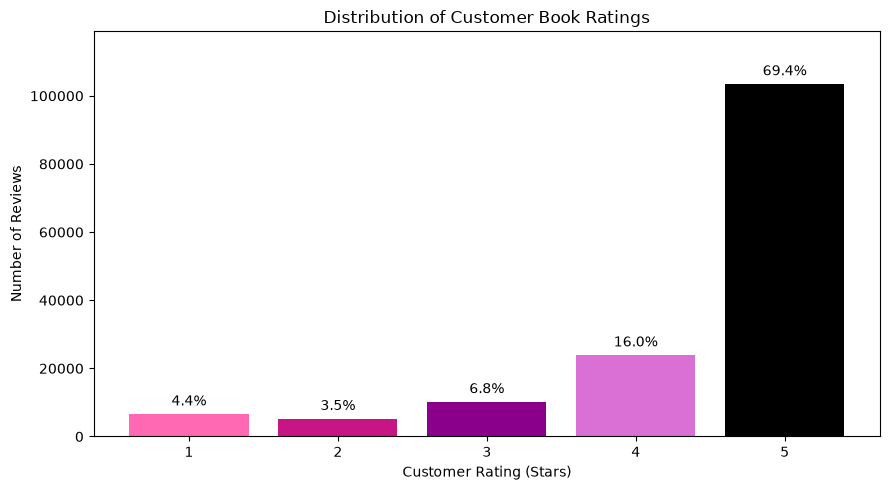

In [22]:
import pandas as pd
import matplotlib.pyplot as plt

# Calculate rating counts and percentages
rating_counts = (
    books_clean["rating"]
    .value_counts()
    .sort_index()
)

rating_summary = pd.DataFrame({
    "Count": rating_counts,
    "Percentage": (
        rating_counts / len(books_clean) * 100
    ).round(2)
})

display(rating_summary)

# Calculate positive rating percentage (4-5 stars)
positive_share = (
    books_clean["rating"].ge(4).mean() * 100
)

print(f"Positive rating share: {positive_share:.2f}%")

# Visualize customer rating distribution
rating_colors = [
    "hotpink",
    "mediumvioletred",
    "darkmagenta",
    "orchid",
    "black"
]

plt.figure(figsize=(9, 5))

bars = plt.bar(
    rating_summary.index,
    rating_summary["Count"],
    color=rating_colors
)

# Display percentages above bars
plt.bar_label(
    bars,
    labels=[
        f"{value:.1f}%"
        for value in rating_summary["Percentage"]
    ],
    padding=4
)

plt.xlabel("Customer Rating (Stars)")
plt.ylabel("Number of Reviews")
plt.title("Distribution of Customer Book Ratings")
plt.xticks([1, 2, 3, 4, 5])
plt.ylim(0, rating_summary["Count"].max() * 1.15)

plt.tight_layout()
plt.show()

### Customer Rating Distribution Interpretation

The rating distribution is heavily concentrated toward positive evaluations, with 85.38% of reviews receiving four or five stars and 69.38% receiving five stars. Ratings of one through three stars account for only 14.62% of observations, indicating substantial class imbalance.

This finding has important implications for predictive modeling. If positive ratings are defined as four or five stars, a model predicting every review as positive would achieve 85.38% accuracy without distinguishing customer preferences. Therefore, model evaluation should extend beyond accuracy to include precision, recall, F1-score, and performance against a majority-class baseline.

These findings describe observed reviewer behavior rather than overall purchasing behavior or customer satisfaction across the Amazon Books market.

### 2. Customer Review Behavior

Unique customers: 51645

Reviews per customer:


count      51645.0
mean      2.886049
std      13.583145
min            1.0
25%            1.0
50%            1.0
75%            2.0
max         1844.0
Name: count, dtype: Float64


Customers with at least 5 reviews: 5996

Top 10 customers' share: 4.76 %


count
1        29940
2         9218
3–4       6491
5–9       3960
10–19     1369
20+        667
Name: count, dtype: int64

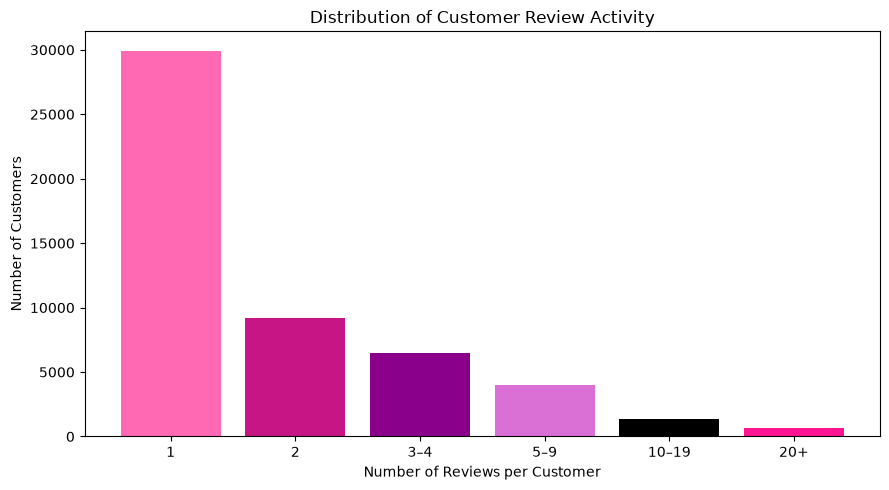

In [23]:
# Calculate customer review frequency
customer_counts = books_clean["user_id"].value_counts()

print("Unique customers:", len(customer_counts))
print("\nReviews per customer:")
display(customer_counts.describe())

print(
    "\nCustomers with at least 5 reviews:",
    (customer_counts >= 5).sum()
)

print(
    "\nTop 10 customers' share:",
    round(customer_counts.head(10).sum()
          / len(books_clean) * 100, 2),
    "%"
)

# Group customers by number of reviews
frequency_groups = pd.cut(
    customer_counts,
    bins=[0, 1, 2, 4, 9, 19, float("inf")],
    labels=["1", "2", "3–4", "5–9", "10–19", "20+"]
)

frequency_summary = (
    frequency_groups.value_counts().sort_index()
)

display(frequency_summary)

# Visualize customer review frequency
plt.figure(figsize=(9, 5))

bars = plt.bar(
    frequency_summary.index,
    frequency_summary.values,
    color=[
        "hotpink", "mediumvioletred",
        "darkmagenta", "orchid",
        "black", "deeppink"
    ]
)

plt.xlabel("Number of Reviews per Customer")
plt.ylabel("Number of Customers")
plt.title("Distribution of Customer Review Activity")
plt.tight_layout()
plt.show()

### Customer Review Behavior Interpretation

The cleaned dataset contains 51,645 unique customers, with an average of 2.89 reviews per customer. Review activity is highly uneven: approximately 57.98% of customers contributed only one review, while 5,996 customers submitted at least five reviews. The ten most active customers account for 4.76% of all observations.

This distribution highlights an important limitation for personalized recommendation modeling. Most customers have relatively little historical interaction data, making it difficult to identify individual preferences. However, customers with more extensive review histories may provide sufficient information to investigate patterns in rating behavior and book preferences.

These findings suggest that customer interaction frequency should be considered when designing and evaluating predictive models. In particular, model performance may differ between customers with limited histories and those with repeated interactions.

### 3. Book Popularity and Review Frequency

Unique books: 118648

Reviews per book:


count    118648.0
mean     1.256237
std      1.545498
min           1.0
25%           1.0
50%           1.0
75%           1.0
max         198.0
Name: count, dtype: Float64


Books with only one review: 104316

Books with at least 5 reviews: 1656

Top 10 books' share of reviews: 0.67 %


count
1      104316
2        9311
3–4      3365
5–9      1248
10+       408
Name: count, dtype: int64

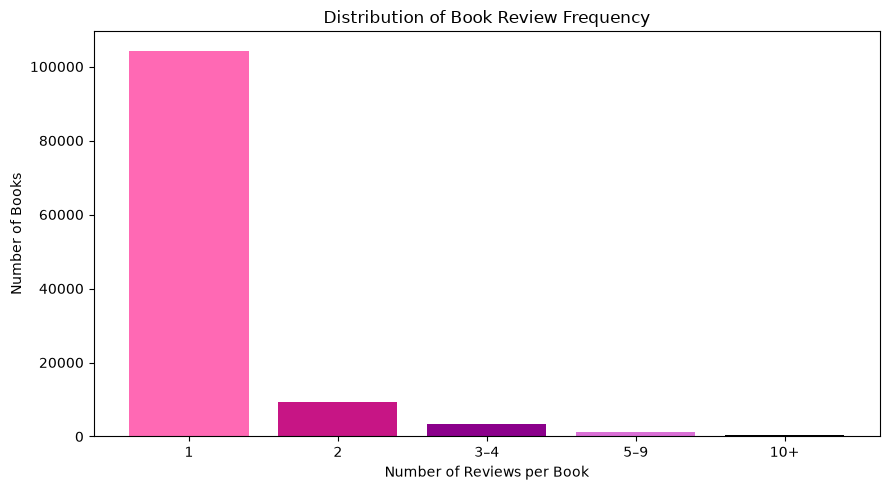

In [24]:
# Calculate review frequency per book
book_counts = books_clean["parent_asin"].value_counts()

print("Unique books:", len(book_counts))

print("\nReviews per book:")
display(book_counts.describe())

print(
    "\nBooks with only one review:",
    (book_counts == 1).sum()
)

print(
    "\nBooks with at least 5 reviews:",
    (book_counts >= 5).sum()
)

print(
    "\nTop 10 books' share of reviews:",
    round(
        book_counts.head(10).sum() /
        len(books_clean) * 100, 2
    ),
    "%"
)

# Group books by review frequency
book_frequency_groups = pd.cut(
    book_counts,
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=["1", "2", "3–4", "5–9", "10+"]
)

book_frequency_summary = (
    book_frequency_groups.value_counts().sort_index()
)

display(book_frequency_summary)

# Visualize book review frequency
plt.figure(figsize=(9, 5))

plt.bar(
    book_frequency_summary.index,
    book_frequency_summary.values,
    color=[
        "hotpink",
        "mediumvioletred",
        "darkmagenta",
        "orchid",
        "black"
    ]
)

plt.xlabel("Number of Reviews per Book")
plt.ylabel("Number of Books")
plt.title("Distribution of Book Review Frequency")
plt.tight_layout()
plt.show()

### Book Popularity and Review Frequency Interpretation

The cleaned dataset contains 118,648 unique books, with an average of 1.26 reviews per book. Review frequency is highly sparse, with 104,316 books (87.92%) appearing only once and only 1,656 books receiving at least five reviews. The ten most-reviewed books collectively account for 0.67% of sampled review observations.

This limited interaction history presents a challenge for personalized recommendation models that rely primarily on repeated customer-book interactions. Combined with the sparse customer histories identified earlier, the findings suggest that incorporating book characteristics may provide useful additional information for predicting customer preferences.

Because the analytical dataset was constructed through customer-based sampling, review frequencies reflect activity within the selected sample rather than overall book popularity on Amazon.

### 4. Book Characteristics and Category Analysis

In [25]:
# Examine categories at the unique-book level
books_unique = books_clean.drop_duplicates(
    subset="parent_asin"
).copy()

print("Unique books:", len(books_unique))

# Examine main category distribution
print("\nMain category distribution:")
display(
    books_unique["main_category"]
    .fillna("Missing")
    .value_counts()
    .head(15)
)

# Check category list completeness
has_categories = books_unique["categories"].apply(
    lambda x: isinstance(x, list) and len(x) > 0
)

print("\nBooks with nonempty category lists:")
print(has_categories.sum())

print("\nBooks with empty or unavailable categories:")
print((~has_categories).sum())

# Inspect examples of category structures
print("\nExamples of book categories:")
display(
    books_unique.loc[
        has_categories,
        ["book_title", "categories"]
    ].head(10)
)

Unique books: 118648

Main category distribution:


main_category
Books                      103478
Buy a Kindle                13665
Audible Audiobooks           1369
                               90
Toys & Games                   15
Office Products                10
Missing                         6
Amazon Home                     6
Arts, Crafts & Sewing           3
Musical Instruments             3
Industrial & Scientific         2
AMAZON FASHION                  1
Name: count, dtype: int64


Books with nonempty category lists:
113031

Books with empty or unavailable categories:
5617

Examples of book categories:


,book_title,categories
0,Best Easy Day Hikes Shenandoah National Park (...,"[Books, Travel, United States]"
1,Winter of the World: Book Two of the Century T...,"[Books, Literature & Fiction, Genre Fiction]"
2,Fault Lines: The Social Justice Movement and E...,"[Books, Christian Books & Bibles, Christian Li..."
3,The Day the World Came to Town: 9/11 in Gander...,"[Books, Travel, Canada]"
4,The Longmire Mystery Series Boxed Set Volumes ...,"[Books, Mystery, Thriller & Suspense, Thriller..."
5,"Happy, Happy, Happy: My Life and Legacy as the...","[Books, Biographies & Memoirs, Arts & Literature]"
6,Tess of the D'Urbervilles (Everyman's Library),"[Books, Literature & Fiction, Genre Fiction]"
7,Tropical Butterflies Stained Glass Coloring Bo...,"[Books, Children's Books, Activities, Crafts &..."
8,Bogie the Boxer: Gardens,"[Books, Children's Books, Animals]"
10,Wish,"[Books, Children's Books, Growing Up & Facts o..."


### Book Category Structure Interpretation

The dataset contains 118,648 unique books, of which 113,031 (95.27%) have nonempty category lists. The remaining 5,617 books (4.73%) have empty or unavailable category information.

The `main_category` variable primarily represents broad Amazon classifications, with most books labeled as Books, Buy a Kindle, or Audible Audiobooks. In contrast, the `categories` variable contains hierarchical classifications such as Literature & Fiction, Travel, and Mystery, Thriller & Suspense.

These more detailed categories may provide useful predictors of customer preferences, particularly for books with limited review histories. Further examination is needed to identify a consistent category level for analysis and determine how missing or irregular classifications should be handled.

In [26]:
# Inspect category hierarchy across unique books
category_lists = books_unique["categories"].apply(
    lambda x: x if isinstance(x, list) else []
)

# Count the number of classification levels
category_depth = category_lists.apply(len)

print("Books with no category levels:",
      (category_depth == 0).sum())

print("Books with one category level:",
      (category_depth == 1).sum())

print("Books with two or more levels:",
      (category_depth >= 2).sum())

# Extract the first and second category levels
first_level = category_lists.apply(
    lambda x: x[0] if len(x) >= 1 else pd.NA
)

second_level = category_lists.apply(
    lambda x: x[1] if len(x) >= 2 else pd.NA
)

print("\nMost common first-level categories:")
display(first_level.value_counts(dropna=False).head(15))

print("\nMost common second-level categories:")
display(second_level.value_counts(dropna=False).head(20))

Books with no category levels: 5617
Books with one category level: 0
Books with two or more levels: 113031

Most common first-level categories:


categories
Books                        112907
NaN                            5617
Audible Books & Originals       124
Name: count, dtype: int64


Most common second-level categories:


categories
Literature & Fiction            20273
Children's Books                14026
Mystery, Thriller & Suspense    11133
Arts & Photography               5665
NaN                              5617
Crafts, Hobbies & Home           5418
Biographies & Memoirs            4444
History                          3952
Teen & Young Adult               3913
Christian Books & Bibles         3762
Business & Money                 3477
Cookbooks, Food & Wine           3447
Politics & Social Sciences       3109
New, Used & Rental Textbooks     2553
Humor & Entertainment            2399
Science Fiction & Fantasy        2337
Reference                        2317
Science & Math                   2267
Computers & Technology           1940
Travel                           1783
Name: count, dtype: int64

### Book Category Hierarchy Interpretation

The category hierarchy assessment found that 113,031 books contain at least two classification levels, while 5,617 have no available category information. The first level primarily identifies broad Amazon product classifications, whereas the second level provides more meaningful literary genres and subject areas.

The largest second-level categories include Literature & Fiction (20,273 books), Children's Books (14,026), and Mystery, Thriller & Suspense (11,133). These classifications offer a useful basis for comparing book characteristics and investigating differences in customer ratings.

For subsequent analysis, the second category level will be used to construct a `book_subcategory` variable. Books without available category information will be retained under an Unknown classification rather than excluded.

Most common book subcategories:


,Book Count,Percentage
book_subcategory,,
Literature & Fiction,20273,17.09
Children's Books,14026,11.82
"Mystery, Thriller & Suspense",11133,9.38
Arts & Photography,5665,4.77
Unknown,5617,4.73
"Crafts, Hobbies & Home",5418,4.57
Biographies & Memoirs,4444,3.75
History,3952,3.33
Teen & Young Adult,3913,3.30


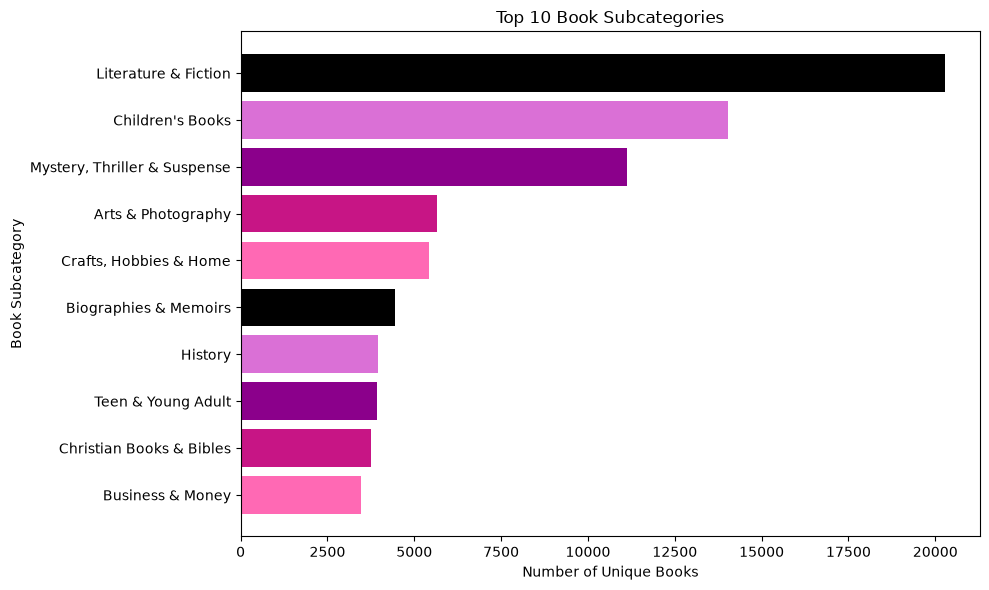

In [27]:
# Extract the second-level book category
def get_book_subcategory(categories):
    if isinstance(categories, list) and len(categories) >= 2:
        category = categories[1]

        if isinstance(category, str) and category.strip():
            return category.strip()

    return "Unknown"


books_clean["book_subcategory"] = (
    books_clean["categories"].apply(get_book_subcategory)
)

# Analyze categories at the unique-book level
books_unique = books_clean.drop_duplicates(
    subset="parent_asin"
).copy()

subcategory_counts = (
    books_unique["book_subcategory"].value_counts()
)

# Calculate category counts and percentages
subcategory_summary = pd.DataFrame({
    "Book Count": subcategory_counts,
    "Percentage": (
        subcategory_counts / len(books_unique) * 100
    ).round(2)
})

print("Most common book subcategories:")
display(subcategory_summary.head(15))

# Plot the ten most common known subcategories
top_categories = (
    subcategory_counts
    .drop(index="Unknown", errors="ignore")
    .head(10)
    .sort_values()
)

category_colors = [
    "hotpink",
    "mediumvioletred",
    "darkmagenta",
    "orchid",
    "black"
]

plt.figure(figsize=(10, 6))

plt.barh(
    top_categories.index,
    top_categories.values,
    color=[
        category_colors[i % len(category_colors)]
        for i in range(len(top_categories))
    ]
)

plt.xlabel("Number of Unique Books")
plt.ylabel("Book Subcategory")
plt.title("Top 10 Book Subcategories")
plt.tight_layout()
plt.show()

### Book Subcategory Distribution Interpretation

The subcategory analysis shows that Literature & Fiction represents the largest share of unique books (17.09%), followed by Children's Books (11.82%) and Mystery, Thriller & Suspense (9.38%). Together, these three categories account for 38.29% of the books in the analytical sample. An additional 4.73% of books were classified as Unknown because detailed category information was unavailable.

The distribution demonstrates substantial variation in category representation, suggesting that book subject matter may be useful for examining differences in customer rating behavior. However, these counts reflect the composition of the sampled books rather than overall market demand or sales.

The next step is to compare ratings across subcategories to determine whether customer evaluations vary by book type and whether category information may contribute to predictive modeling.

### 4.1 Customer Ratings by Book Subcategory

Customer ratings by book subcategory:


,review_count,unique_books,average_rating,positive_pct
book_subcategory,,,,
Christian Books & Bibles,4320,3762,4.67,92.55
Children's Books,18349,14026,4.60,89.64
History,4493,3952,4.46,87.45
Biographies & Memoirs,5414,4444,4.46,87.13
Arts & Photography,6459,5665,4.47,86.16
"Crafts, Hobbies & Home",6393,5418,4.46,85.72
Teen & Young Adult,4919,3913,4.36,84.83
Business & Money,4006,3477,4.40,84.17
Literature & Fiction,26535,20273,4.35,83.62


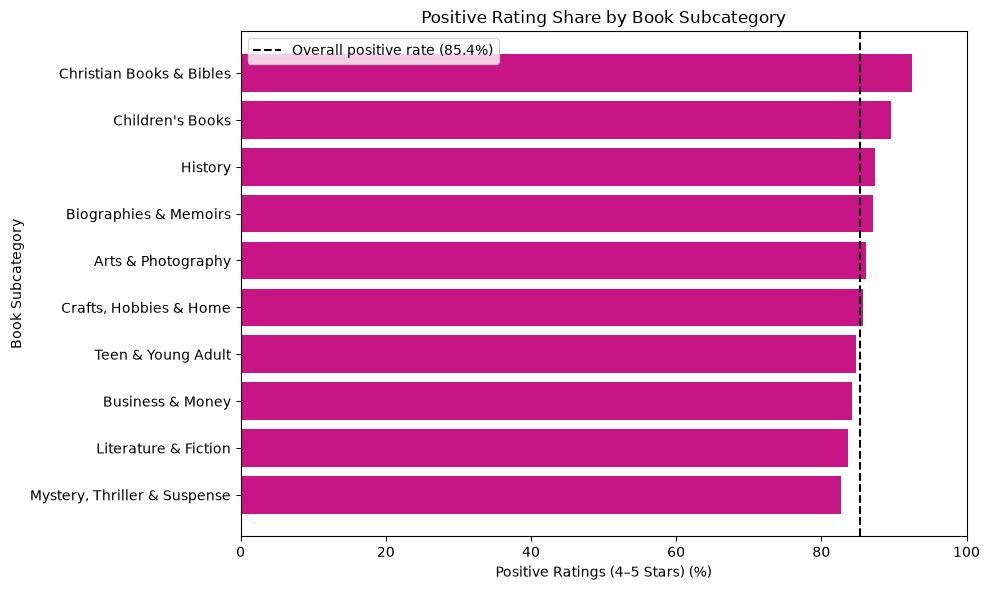

In [28]:
# Identify the 10 largest known book subcategories
top_10_categories = (
    books_unique["book_subcategory"]
    .value_counts()
    .drop(index="Unknown", errors="ignore")
    .head(10)
    .index
)

# Compare ratings across subcategories
category_ratings = (
    books_clean[
        books_clean["book_subcategory"].isin(top_10_categories)
    ]
    .assign(positive_rating=lambda x: x["rating"] >= 4)
    .groupby("book_subcategory")
    .agg(
        review_count=("rating", "size"),
        unique_books=("parent_asin", "nunique"),
        average_rating=("rating", "mean"),
        positive_share=("positive_rating", "mean")
    )
)

# Convert positive share to percentage
category_ratings["positive_pct"] = (
    category_ratings["positive_share"] * 100
)

print("Customer ratings by book subcategory:")

display(
    category_ratings[
        ["review_count", "unique_books",
         "average_rating", "positive_pct"]
    ].sort_values("positive_pct", ascending=False).round(2)
)

# Visualize positive rating percentages
plot_data = category_ratings.sort_values("positive_pct")

plt.figure(figsize=(10, 6))

plt.barh(
    plot_data.index,
    plot_data["positive_pct"],
    color="mediumvioletred"
)

# Overall positive rating baseline
overall_positive = books_clean["rating"].ge(4).mean() * 100

plt.axvline(
    overall_positive,
    color="black",
    linestyle="--",
    label=f"Overall positive rate ({overall_positive:.1f}%)"
)

plt.xlabel("Positive Ratings (4–5 Stars) (%)")
plt.ylabel("Book Subcategory")
plt.title("Positive Rating Share by Book Subcategory")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

### Customer Ratings by Book Subcategory Interpretation

Positive-rating percentages vary across the ten largest book subcategories. Christian Books & Bibles has the highest positive-rating share (92.55%), followed by Children's Books (89.64%), while Mystery, Thriller & Suspense (82.73%) and Literature & Fiction (83.62%) fall below the overall positive-rating baseline of 85.38%.

The 9.82-percentage-point difference between the highest- and lowest-rated categories suggests that book subject matter may be associated with customer evaluations. These findings support considering `book_subcategory` as a potential predictive feature. However, the differences are descriptive associations and do not establish that book categories cause higher or lower ratings.

The results also reflect customers who submitted reviews, rather than all Amazon customers or actual purchase behavior.

### 4.2 Book Price Distribution

Unique books: 118648
Books with usable prices: 93787
Price coverage: 79.05 %

Price summary:


count    93787.000000
mean        20.256138
std         57.920665
min          0.010000
25%          8.990000
50%         13.790000
75%         19.990000
90%         33.960000
95%         49.950000
99%        126.415400
max       9653.810000
Name: price_for_eda, dtype: float64


99th percentile: $126.42
Prices excluded from chart only: 938


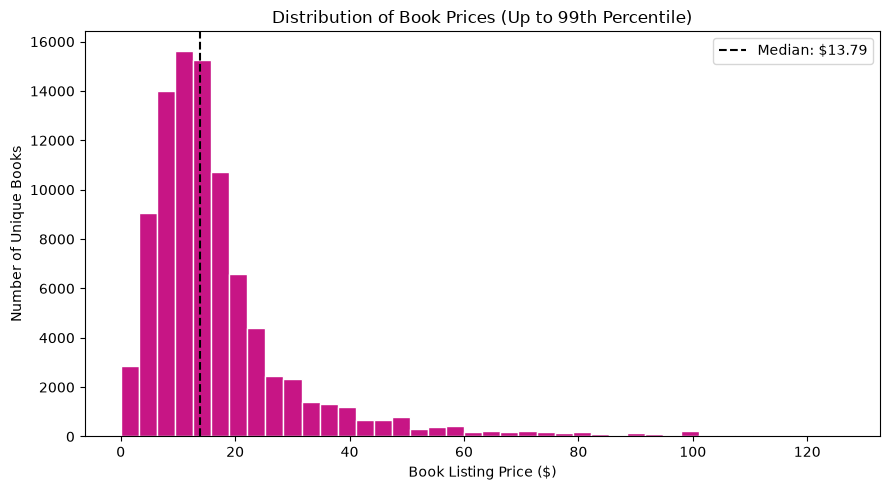

In [29]:
# Analyze prices at the unique-book level
books_unique = books_clean.drop_duplicates(
    subset="parent_asin"
).copy()

book_prices = (
    books_unique["price_for_eda"]
    .dropna()
    .astype(float)
)

# Price coverage and descriptive statistics
print("Unique books:", len(books_unique))
print("Books with usable prices:", len(book_prices))

print(
    "Price coverage:",
    round(len(book_prices) / len(books_unique) * 100, 2),
    "%"
)

print("\nPrice summary:")
display(
    book_prices.describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

# Limit the visualization to the 99th percentile
price_limit = book_prices.quantile(0.99)

plot_prices = book_prices[
    book_prices <= price_limit
]

print(f"\n99th percentile: ${price_limit:.2f}")
print("Prices excluded from chart only:",
      len(book_prices) - len(plot_prices))

# Visualize book prices
plt.figure(figsize=(9, 5))

plt.hist(
    plot_prices,
    bins=40,
    color="mediumvioletred",
    edgecolor="white"
)

plt.axvline(
    book_prices.median(),
    color="black",
    linestyle="--",
    label=f"Median: ${book_prices.median():.2f}"
)

plt.xlabel("Book Listing Price ($)")
plt.ylabel("Number of Unique Books")
plt.title("Distribution of Book Prices (Up to 99th Percentile)")
plt.legend()
plt.tight_layout()
plt.show()

### Book Price Distribution Interpretation

Of the 118,648 unique books in the analytical sample, 93,787 (79.05%) have usable positive numeric prices. The price distribution is strongly right-skewed, with a median of USD 13.79 and a mean of $20.26. Approximately 75% of books with usable prices are listed at or below USD 19.99, while a small number of unusually expensive listings extend the distribution considerably.

To improve visualization, the histogram was restricted to the 99th percentile ($126.42), excluding 938 observations from the chart only. All prices were retained in the analytical dataset.

These findings demonstrate considerable variation in book listing prices, suggesting that price may be worth examining alongside customer ratings. However, the recorded prices are product metadata rather than confirmed transaction prices and may not reflect prices at the time reviews were submitted.

### 4.3 Customer Ratings by Book Price

Customer ratings by book price range:


,review_count,unique_books,average_rating,positive_pct
price_band,,,,
Under $10,40884,31320,4.40,84.66
$10–<$20,50191,39691,4.43,85.55
$20–<$40,18157,15933,4.46,86.17
$40+,7431,6843,4.43,85.37


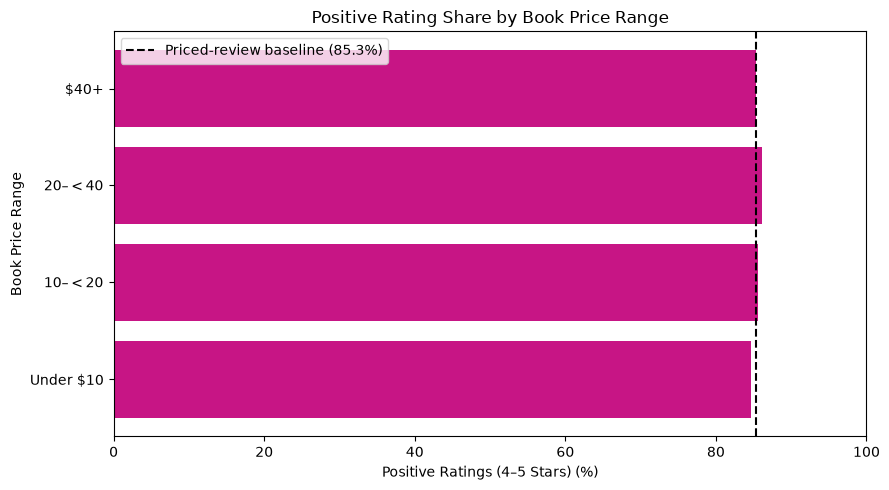

In [30]:
# Select reviews with usable book prices
priced_reviews = books_clean.loc[
    books_clean["price_for_eda"].notna(),
    ["rating", "parent_asin", "price_for_eda"]
].copy()

# Create interpretable price ranges
priced_reviews["price_band"] = pd.cut(
    priced_reviews["price_for_eda"].astype(float),
    bins=[0, 10, 20, 40, float("inf")],
    labels=[
        "Under $10",
        "$10–<$20",
        "$20–<$40",
        "$40+"
    ],
    right=False
)

# Identify positive customer ratings
priced_reviews["positive_rating"] = (
    priced_reviews["rating"] >= 4
)

# Compare ratings across price ranges
price_rating_summary = (
    priced_reviews
    .groupby("price_band", observed=True)
    .agg(
        review_count=("rating", "size"),
        unique_books=("parent_asin", "nunique"),
        average_rating=("rating", "mean"),
        positive_share=("positive_rating", "mean")
    )
)

price_rating_summary["positive_pct"] = (
    price_rating_summary["positive_share"] * 100
)

print("Customer ratings by book price range:")

display(
    price_rating_summary[
        ["review_count", "unique_books",
         "average_rating", "positive_pct"]
    ].round(2)
)

# Baseline among reviews with usable prices
priced_positive_baseline = (
    priced_reviews["positive_rating"].mean() * 100
)

# Visualize positive rating percentages
plt.figure(figsize=(9, 5))

plt.barh(
    price_rating_summary.index.astype(str),
    price_rating_summary["positive_pct"],
    color="mediumvioletred"
)

plt.axvline(
    priced_positive_baseline,
    color="black",
    linestyle="--",
    label=f"Priced-review baseline ({priced_positive_baseline:.1f}%)"
)

plt.xlabel("Positive Ratings (4–5 Stars) (%)")
plt.ylabel("Book Price Range")
plt.title("Positive Rating Share by Book Price Range")
plt.xlim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

### Customer Ratings by Book Price Interpretation

Positive-rating percentages are relatively consistent across book price ranges, varying from 84.66% for books under USD 10 to 86.17% for books priced between USD 20 and USD 40. The highest-priced group (USD 40 and above) has a positive-rating share of 85.37%, indicating no consistent increase in favorable ratings as price rises.

The difference of 1.51 percentage points between the highest- and lowest-rated price groups is substantially smaller than the variation observed across book subcategories. This suggests that listing price may provide less predictive information about customer ratings than book subject matter, although its contribution must be evaluated through modeling.

These findings represent descriptive associations rather than causal relationships, and the available prices may not reflect amounts paid by customers at the time of their reviews.

### 5. Review Activity Over Time

Review activity by year:


,review_count,unique_customers,average_rating,positive_pct
review_year,,,,
1997,14,10,4.79,100.00
1998,132,78,4.26,81.06
1999,219,147,4.34,83.56
2000,769,322,4.22,81.27
2001,806,281,4.24,81.14
2002,800,321,4.26,83.12
2003,905,369,4.11,76.02
2004,1014,388,4.09,75.44
2005,1352,610,4.11,76.63


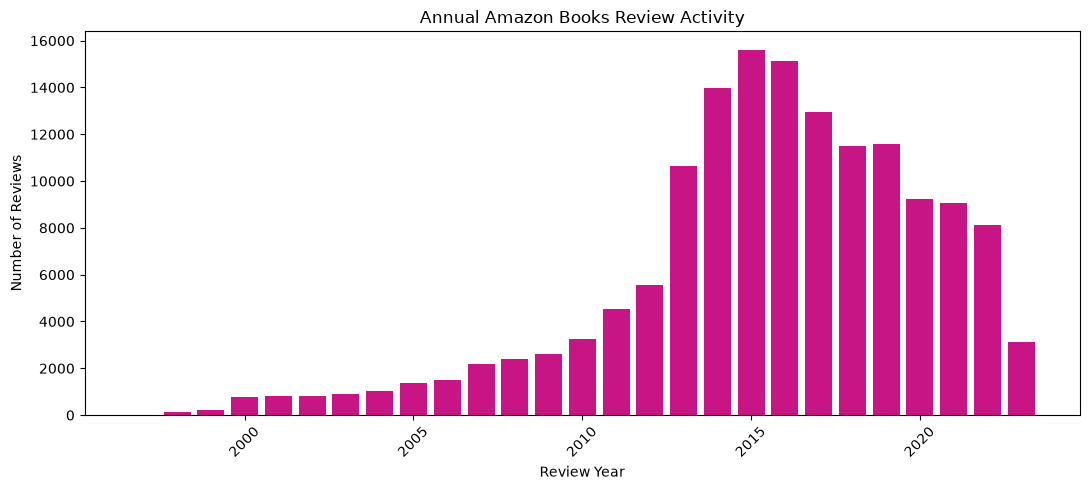

In [31]:
# Extract review year
books_clean["review_year"] = (
    pd.to_datetime(books_clean["timestamp"], errors="coerce")
    .dt.year
)

# Summarize annual review activity
yearly_reviews = (
    books_clean
    .assign(positive_rating=books_clean["rating"] >= 4)
    .groupby("review_year")
    .agg(
        review_count=("rating", "size"),
        unique_customers=("user_id", "nunique"),
        average_rating=("rating", "mean"),
        positive_share=("positive_rating", "mean")
    )
)

# Convert positive share to percentage
yearly_reviews["positive_pct"] = (
    yearly_reviews["positive_share"] * 100
)

print("Review activity by year:")

display(
    yearly_reviews[
        ["review_count", "unique_customers",
         "average_rating", "positive_pct"]
    ].round(2)
)

# Visualize annual review activity
plt.figure(figsize=(11, 5))

plt.bar(
    yearly_reviews.index.astype(int),
    yearly_reviews["review_count"],
    color="mediumvioletred"
)

plt.xlabel("Review Year")
plt.ylabel("Number of Reviews")
plt.title("Annual Amazon Books Review Activity")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Review Activity Over Time Interpretation

Annual review activity increased substantially through the mid-2010s, reaching a peak of 15,618 observations in 2015 before declining in subsequent years. Positive-rating percentages also varied over time, increasing from 75.44% in 2004 to 87.50% in 2019, followed by a modest decline to 85.12% in 2022.

These patterns suggest that review activity and rating behavior may differ across historical periods. However, the results reflect the selected customer-based sample and should not be interpreted as direct measures of Amazon's overall sales or customer activity. Additionally, the incomplete coverage of 2023 limits comparisons with full calendar years.

The observed temporal variation suggests that review year may be useful for further exploratory analysis. It also supports considering chronological data splitting during predictive modeling to evaluate performance on later observations and reduce the risk of temporal data leakage.

### 5.1 Positive Rating Trends Over Time

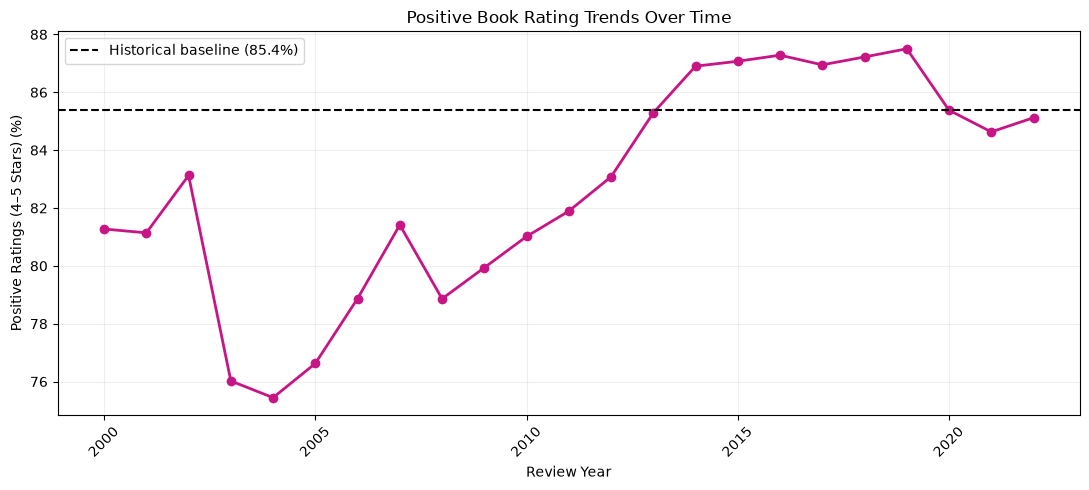

In [32]:
# Focus on years with sufficient review observations
# Exclude incomplete 2023 for historical comparison
yearly_trends = yearly_reviews.loc[
    (yearly_reviews.index <= 2022)
    & (yearly_reviews["review_count"] >= 500)
].copy()

# Calculate baseline for the selected years
historical_baseline = (
    books_clean.loc[
        books_clean["review_year"].isin(yearly_trends.index),
        "rating"
    ].ge(4).mean() * 100
)

# Visualize positive-rating trends
plt.figure(figsize=(11, 5))

plt.plot(
    yearly_trends.index,
    yearly_trends["positive_pct"],
    color="mediumvioletred",
    marker="o",
    linewidth=2
)

plt.axhline(
    historical_baseline,
    color="black",
    linestyle="--",
    label=f"Historical baseline ({historical_baseline:.1f}%)"
)

plt.xlabel("Review Year")
plt.ylabel("Positive Ratings (4–5 Stars) (%)")
plt.title("Positive Book Rating Trends Over Time")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Positive Rating Trends Over Time Interpretation

The positive-rating trend shows substantial variation across the historical period, increasing from a low of 75.44% in 2004 to 87.50% in 2019. Positive ratings remained relatively stable around 87% during 2014–2019 before declining to 84.63% in 2021 and recovering slightly to 85.12% in 2022.

These findings suggest that the distribution of customer ratings may change over time, which has implications for predictive modeling. A chronological training and testing approach may help evaluate how well models generalize to later observations rather than relying exclusively on randomly selected records.

However, the observed trends are descriptive and may reflect changes in reviewer composition, book characteristics, or data coverage rather than changes in overall customer satisfaction.

### 6. Relationships Between Book Characteristics

price_band,Under $10,$10–<$20,$20–<$40,$40+
book_subcategory,,,,
Literature & Fiction,82.65,83.38,81.72,83.03
Children's Books,89.34,90.48,88.65,89.38
"Mystery, Thriller & Suspense",83.00,79.00,77.43,83.49
Arts & Photography,84.54,85.53,87.29,88.48
"Crafts, Hobbies & Home",82.95,85.67,87.91,87.26
Biographies & Memoirs,87.38,86.99,88.80,84.19
History,83.08,88.06,89.71,90.69
Teen & Young Adult,83.66,84.85,87.27,87.84
Christian Books & Bibles,91.49,92.99,92.92,91.72


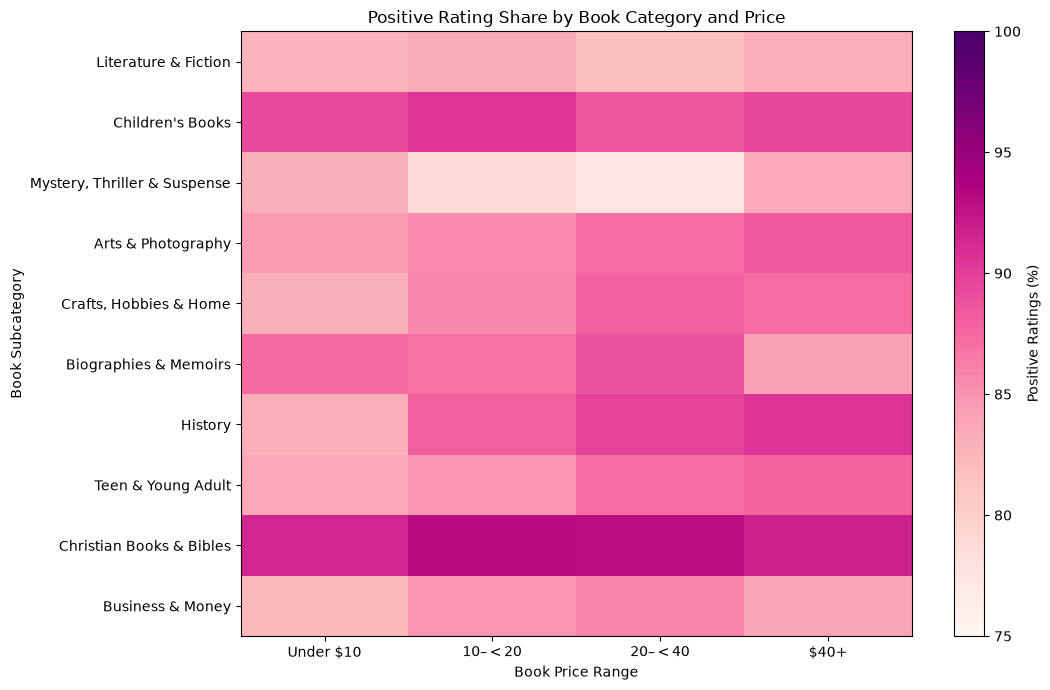

In [33]:
# Examine price and category relationships together
top_categories = (
    books_unique["book_subcategory"]
    .value_counts()
    .drop(index="Unknown", errors="ignore")
    .head(10)
    .index
)

feature_data = books_clean.loc[
    books_clean["book_subcategory"].isin(top_categories)
    & books_clean["price_for_eda"].notna(),
    ["book_subcategory", "price_for_eda", "rating"]
].copy()

# Create price bands
price_labels = [
    "Under $10", "$10–<$20", "$20–<$40", "$40+"
]

feature_data["price_band"] = pd.cut(
    feature_data["price_for_eda"].astype(float),
    bins=[0, 10, 20, 40, float("inf")],
    labels=price_labels,
    right=False
)

feature_data["positive_rating"] = (
    feature_data["rating"] >= 4
)

# Calculate positive rating percentages and sample sizes
relationship_summary = (
    feature_data
    .groupby(["book_subcategory", "price_band"], observed=True)
    .agg(
        review_count=("rating", "size"),
        positive_pct=("positive_rating", "mean")
    )
)

relationship_summary["positive_pct"] *= 100

# Reshape results for visualization
positive_matrix = (
    relationship_summary["positive_pct"]
    .unstack("price_band")
    .reindex(index=top_categories, columns=price_labels)
)

count_matrix = (
    relationship_summary["review_count"]
    .unstack("price_band")
    .reindex(index=top_categories, columns=price_labels)
)

# Hide groups with fewer than 100 reviews
positive_matrix = positive_matrix.where(
    count_matrix >= 100
)

display(positive_matrix.round(2))

# Create heat map
plt.figure(figsize=(11, 7))

plt.imshow(
    positive_matrix.astype(float),
    aspect="auto",
    cmap="RdPu",
    vmin=75,
    vmax=100
)

plt.colorbar(label="Positive Ratings (%)")

plt.xticks(
    range(len(positive_matrix.columns)),
    positive_matrix.columns
)

plt.yticks(
    range(len(positive_matrix.index)),
    positive_matrix.index
)

plt.xlabel("Book Price Range")
plt.ylabel("Book Subcategory")
plt.title("Positive Rating Share by Book Category and Price")

plt.tight_layout()
plt.show()

### Relationships Between Book Characteristics Interpretation

The heat map shows that positive-rating patterns vary across book subcategories and price ranges. Christian Books & Bibles consistently exhibits relatively high positive-rating percentages, while Mystery, Thriller & Suspense and Literature & Fiction generally show lower percentages. Price-related patterns also differ across categories, with no consistent relationship between higher listing prices and more favorable customer ratings.

These findings suggest that book subcategory may be more informative than price alone when examining customer evaluations. They also indicate that the relationship between price and ratings may depend on book category. However, these descriptive associations do not establish causality or predictive importance.

The results support evaluating category and price as potential modeling features, while accounting for reviewer differences, incomplete pricing information, and the historical availability of product metadata.

In [34]:
# Display positive-rating percentages and review counts
# for each category-price combination

category_price_details = relationship_summary[
    ["review_count", "positive_pct"]
].copy()

# Retain combinations with at least 100 reviews
category_price_details = category_price_details.loc[
    category_price_details["review_count"] >= 100
]

print("Category and price relationship details:")

display(
    category_price_details.round(2)
)

# Examine variation in positive ratings across price
# bands within each book subcategory
category_price_spread = (
    positive_matrix.max(axis=1)
    - positive_matrix.min(axis=1)
)

print("\nPositive-rating variation across price bands:")
display(
    category_price_spread
    .sort_values(ascending=False)
    .round(2)
)

Category and price relationship details:


review_count  positive_pct
book_subcategory             price_band                            
Arts & Photography           Under $10           1164         84.54
                             $10–<$20            1901         85.53
                             $20–<$40            1471         87.29
                             $40+                 781         88.48
Biographies & Memoirs        Under $10            832         87.38
                             $10–<$20            2582         86.99
                             $20–<$40            1009         88.80
                             $40+                 215         84.19
Business & Money             Under $10            813         82.16
                             $10–<$20            1691         84.98
                             $20–<$40             701         85.88
                             $40+                 248         83.87
Children's Books             Under $10           8989         89.34
                             $10–<$20            5357         90.48
                             $20–<$40             969         88.65
                             $40+                 405         89.38
Christian Books & Bibles     Under $10            940         91.49
                             $10–<$20            2140         92.99
                             $20–<$40             551         92.92
                             $40+                 169         91.72
Crafts, Hobbies & Home       Under $10           1472         82.95
                             $10–<$20            2122         85.67
                             $20–<$40            1307         87.91
                             $40+                 424         87.26
History                      Under $10            585         83.08
                             $10–<$20            1793         88.06
                             $20–<$40            1166         89.71
                             $40+                 290         90.69
Literature & Fiction         Under $10           7278         82.65
                             $10–<$20           10103         83.38
                             $20–<$40            1920         81.72
                             $40+                 501         83.03
Mystery, Thriller & Suspense Under $10           6819         83.00
                             $10–<$20            4266         79.00
                             $20–<$40             514         77.43
                             $40+                 109         83.49
Teen & Young Adult           Under $10           1646         83.66
                             $10–<$20            1993         84.85
                             $20–<$40             330         87.27
                             $40+                 148         87.84


Positive-rating variation across price bands:


book_subcategory
History                         7.61
Mystery, Thriller & Suspense    6.05
Crafts, Hobbies & Home          4.96
Biographies & Memoirs           4.61
Teen & Young Adult              4.18
Arts & Photography              3.94
Business & Money                3.71
Children's Books                1.83
Literature & Fiction            1.66
Christian Books & Bibles        1.50
dtype: float64

### Category and Price Relationship Validation

The detailed category-price comparison confirms that positive-rating patterns vary across book subcategories. History exhibits the greatest variation across price bands (7.61 percentage points), followed by Mystery, Thriller & Suspense (6.05 points). In contrast, Christian Books & Bibles (1.50 points) and Literature & Fiction (1.66 points) demonstrate relatively stable positive-rating percentages.

These results suggest that the association between listing price and customer ratings may depend on book category rather than following a consistent pattern across all books. However, some category-price combinations contain relatively few reviews, and differences may reflect reviewer characteristics, product composition, or other unobserved factors.

Overall, the findings support considering book subcategory and price as potential predictive features while emphasizing that descriptive relationships do not necessarily establish predictive importance or causality.

### Modeling Readiness and Feature Availability

In [35]:
# Assess availability of potential modeling features
model_audit = books_clean.copy()

# Provisional classification target
model_audit["positive_rating"] = (
    model_audit["rating"] >= 4
)

# Flag available book characteristics
model_audit["price_available"] = (
    model_audit["price_for_eda"].notna()
)

model_audit["category_available"] = (
    model_audit["book_subcategory"] != "Unknown"
)

# Compare rating outcomes by feature availability
for feature in ["price_available", "category_available"]:

    print(f"\nPositive ratings by {feature}:")

    summary = (
        model_audit
        .groupby(feature)
        .agg(
            review_count=("rating", "size"),
            positive_pct=("positive_rating", "mean")
        )
    )

    summary["positive_pct"] *= 100

    display(summary.round(2))


Positive ratings by price_available:


,review_count,positive_pct
price_available,,
False,32387,85.57
True,116663,85.32



Positive ratings by category_available:


,review_count,positive_pct
category_available,,
False,5809,86.21
True,143241,85.34


### Modeling Readiness and Feature Availability Interpretation

The feature-availability assessment found relatively small differences in positive-rating percentages between observations with and without usable book characteristics. Reviews with available prices had an 85.32% positive-rating share, compared with 85.57% for those without usable prices. Similarly, reviews with available categories had an 85.34% positive-rating share, compared with 86.21% for those without category information.

These results suggest that missing metadata is not associated with large differences in overall positive-rating percentages. However, the findings do not establish that missingness is random or that excluding incomplete observations would introduce no bias.

Retaining incomplete observations is therefore appropriate for the modeling handoff. Missing-price treatment and categorical encoding should be determined within the modeling pipeline, with preprocessing fitted on training data to avoid data leakage.

### Modeling Dataset Preparation

In [36]:
# Select fields for the modeling handoff
handoff_columns = [
    "user_id",
    "parent_asin",
    "timestamp",
    "main_category",
    "book_subcategory",
    "price_for_eda",
    "price_status"
]

model_handoff = books_clean[handoff_columns].copy()

# Define provisional binary classification target
# 1 = positive rating (4-5 stars)
# 0 = nonpositive rating (1-3 stars)
model_handoff["positive_rating"] = (
    books_clean["rating"] >= 4
).astype(int)

# Verify the handoff
print("Modeling dataset shape:", model_handoff.shape)

print("\nTarget distribution:")
print(model_handoff["positive_rating"].value_counts())

print("\nMissing values:")
print(model_handoff.isna().sum())

# Export candidate dataset
model_handoff.to_csv(
    "books_modeling_handoff_candidate.csv",
    index=False
)

print("\nCandidate modeling dataset saved!")

Modeling dataset shape: (149050, 8)

Target distribution:
positive_rating
1    127253
0     21797
Name: count, dtype: int64

Missing values:
user_id                 0
parent_asin             0
timestamp               0
main_category          10
book_subcategory        0
price_for_eda       32387
price_status            0
positive_rating         0
dtype: int64

Candidate modeling dataset saved!


### Modeling Dataset Handoff Validation

The modeling handoff dataset contains 149,050 observations and eight variables, including customer and book identifiers, review timestamps, book characteristics, and a provisional binary classification target. The target identifies 127,253 positive ratings (85.38%) and 21,797 nonpositive ratings (14.62%), confirming substantial class imbalance.

The dataset retains all cleaned review observations, including 32,387 records without usable numeric prices and 10 records with missing main-category information. Missing-value treatment, categorical encoding, and feature selection will be addressed during modeling.

This dataset serves as a reproducible candidate handoff for classification analysis. However, the team must establish which predictors would be available before a customer submits a review and select an appropriate validation strategy to prevent data leakage.

## Overall EDA Findings and Modeling Recommendations

### Key Findings

Exploratory data analysis was conducted on 149,050 cleaned Amazon Books reviews, representing 51,645 customers and 118,648 unique books. The analysis identified several patterns relevant to predicting customer ratings and supporting personalized book recommendations.

**Customer ratings and interaction patterns:** Customer evaluations are heavily skewed toward positive ratings, with 85.38% receiving four or five stars. Additionally, approximately 58% of customers contributed only one review, while 87.92% of books received only one review within the sample. This limited interaction history presents challenges for identifying individual customer preferences.

**Book characteristics:** Positive-rating percentages varied meaningfully across book subcategories. Christian Books & Bibles had the highest positive-rating share among the ten largest categories (92.55%), while Mystery, Thriller & Suspense had the lowest (82.73%). In contrast, positive-rating percentages across price bands ranged from 84.66% to 86.17%, suggesting a weaker overall association between listing price and ratings. Further analysis indicated that price-related patterns differed across book categories.

**Temporal patterns and data quality:** Positive-rating percentages varied across historical periods, suggesting potential changes in rating distributions over time. Missing and inconsistent price information also required additional processing. Rather than discarding incomplete observations, the dataset retained missing-value indicators and preserved available customer interactions.

### Modeling Recommendations

The findings support evaluating classification methods, including logistic regression and random forest, to predict whether an observed customer review receives a positive rating (4–5 stars).

Because 85.38% of reviews are positive, models should be evaluated against a majority-class baseline rather than relying exclusively on accuracy. Precision, recall, F1-score, and confusion matrices will be particularly important for assessing performance on nonpositive ratings.

Book subcategory and price should be evaluated as potential predictors, with appropriate categorical encoding and missing-value treatment. Preprocessing should be fitted using training data only, while chronological and customer-aware validation strategies should be considered to minimize data leakage. Features derived from completed reviews or future customer activity should not be used for predictions intended to occur before a review is submitted.

### Business Implications and Limitations

The EDA suggests that book characteristics may help distinguish patterns in customer evaluations. However, limited customer and book interaction histories present challenges for developing individualized recommendations.

The current modeling dataset primarily captures book characteristics rather than established customer preferences. Stronger personalization would require additional features derived from customers' prior interactions. Furthermore, the available data represent submitted reviews rather than complete purchasing behavior, so findings should not be interpreted as direct evidence of sales performance.

Overall, the analysis provides a foundation for comparing predictive models and identifying whether book characteristics contribute useful information beyond baseline rating patterns.

In [37]:
import numpy as np, pandas as pd, time, warnings
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score, balanced_accuracy_score,
                             f1_score, precision_score, recall_score, roc_curve, precision_recall_curve,
                             confusion_matrix, log_loss, brier_score_loss)
warnings.filterwarnings("ignore")
RANDOM_STATE = 42

df = model_handoff

**Data Subsets**
First we will split our data into training, validation, and test data sets. We will use different date ranges in order to make our subset divisions.

In [38]:
n = len(df)
train_end, val_end = int(n * 0.70), int(n * 0.85)
df["split"] = np.where(df.index < train_end, "train", np.where(df.index < val_end, "val", "test"))

p_bar = df.loc[df.split == "train", "positive_rating"].mean()
M = 5

def add_history(frame, key, prefix):
    g = frame.groupby(key, sort=False)["positive_rating"]
    prior_n = g.cumcount()                                   # reviews strictly before this one
    prior_pos = g.cumsum() - frame["positive_rating"]        # positives strictly before this one
    frame[f"{prefix}_prior_n"] = prior_n
    frame[f"{prefix}_prior_rate"] = (prior_pos + M * p_bar) / (prior_n + M)

add_history(df, "user_id", "user")
add_history(df, "parent_asin", "book")

df["price_missing"] = df["price_for_eda"].isna().astype(int)
df["log_price"] = np.log1p(df["price_for_eda"])
df["year"] = df["timestamp"].dt.year
df["main_category"] = df["main_category"].fillna("Unknown")

# Sanity check: no feature uses the row's own target
chk = df[df.user_id == df.user_id.value_counts().index[3]].head(4)[["timestamp","positive_rating","user_prior_n","user_prior_rate"]]
print(chk)

for s in ["train", "val", "test"]:
    d = df[df.split == s]
    print(f"{s:5s} n={len(d):6d}  {d.timestamp.min().date()} -> {d.timestamp.max().date()}  positive rate={d.positive_rating.mean():.4f}")

                    timestamp  positive_rating  user_prior_n  user_prior_rate
46559 2020-02-09 05:36:27.053                1             0         0.853712
46560 2020-02-08 21:57:51.738                1             1         0.878093
46561 2020-01-27 20:23:18.301                1             2         0.895508
46562 2020-01-27 19:47:48.807                1             3         0.908570
train n=104335  1997-09-30 -> 2023-05-14  positive rate=0.8537
val   n= 22357  1997-09-29 -> 2023-06-18  positive rate=0.8555
test  n= 22358  1997-09-01 -> 2023-09-12  positive rate=0.8522


In [39]:
META_NUM = ["log_price", "price_missing", "year"]
META_CAT = ["price_status", "main_category", "book_subcategory"]
HIST_NUM = ["user_prior_n", "user_prior_rate", "book_prior_n", "book_prior_rate"]

# user_prior_n / book_prior_n are heavy-tailed -> log transform
for c in ["user_prior_n", "book_prior_n"]:
    df[c] = np.log1p(df[c])

ALL_FEATURES = META_NUM + META_CAT + HIST_NUM
tr, va, te = (df[df.split == s] for s in ["train", "val", "test"])
y_tr, y_va, y_te = tr.positive_rating.values, va.positive_rating.values, te.positive_rating.values

def make_preprocessor(num_cols, cat_cols):
    parts = []
    if num_cols:
        parts.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                                       ("sc", StandardScaler())]), num_cols))
    if cat_cols:
        parts.append(("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=200), cat_cols))
    return ColumnTransformer(parts)

def evaluate(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    return {"ROC-AUC": roc_auc_score(y, p), "PR-AUC": average_precision_score(y, p),
            "Log loss": log_loss(y, np.clip(p, 1e-6, 1-1e-6)),
            "Accuracy": accuracy_score(y, pred), "Balanced acc.": balanced_accuracy_score(y, pred),
            "F1 (negative)": f1_score(y, pred, pos_label=0, zero_division=0),
            "Recall (negative)": recall_score(y, pred, pos_label=0, zero_division=0)}

def best_threshold(y, p):
    # threshold maximising balanced accuracy on VALIDATION data
    grid = np.linspace(0.05, 0.95, 91)
    return grid[np.argmax([balanced_accuracy_score(y, (p >= t).astype(int)) for t in grid])]

## Baseline models

Because ~85% of ratings are positive, **accuracy alone is misleading**: always predicting "positive" scores ~85% while identifying no unhappy customers. So we also track ROC-AUC, PR-AUC, log loss, and balanced accuracy / F1 on the minority (not-positive) class.

Baselines:
- **Majority class:** always predict positive.
- **Prior probability:** predict the training positive rate for everyone (zero ranking ability, AUC = 0.5).
- **Simple heuristic:** predict using the customer's prior positive rate alone (a "customer history only" rule).

In [40]:
rows = {}
maj = DummyClassifier(strategy="most_frequent").fit(tr[ALL_FEATURES], y_tr)
rows["Baseline: always positive"] = evaluate(y_te, maj.predict_proba(te[ALL_FEATURES])[:, 1], 0.5)

prior = DummyClassifier(strategy="prior").fit(tr[ALL_FEATURES], y_tr)
rows["Baseline: training prior"] = evaluate(y_te, prior.predict_proba(te[ALL_FEATURES])[:, 1], 0.5)

thr_h = best_threshold(y_va, va["user_prior_rate"].values)
rows["Baseline: customer history rule"] = evaluate(y_te, te["user_prior_rate"].values, thr_h)

baseline_df = pd.DataFrame(rows).T.round(4)
baseline_df

,ROC-AUC,PR-AUC,Log loss,Accuracy,Balanced acc.,F1 (negative),Recall (negative)
Baseline: always positive,0.5000,0.8522,2.0416,0.8522,0.5000,0.0000,0.0000
Baseline: training prior,0.5000,0.8522,0.4188,0.8522,0.5000,0.0000,0.0000
Baseline: customer history rule,0.6108,0.8864,0.4035,0.3959,0.5682,0.2845,0.8127


We will use the always positive model for our baseline.

## Candidate models

Four different models are tested to see their predictive power and compare them to the baseline model, logistic regression, decision tree, random forest, and k-nearest neighbors. Because of the high baseline accuracy for an always positive model and the strategic interest in negative responses, we are most interested in testing ROC AUC, F1 negative and Recall negative values.

In [41]:
from itertools import product
pre = lambda: make_preprocessor(META_NUM + HIST_NUM, META_CAT)

grids = {
    "Logistic Regression": (lambda **k: LogisticRegression(max_iter=2000, **k),
                            [dict(C=c) for c in [0.01, 0.1, 1, 10]]),
    "Decision Tree": (lambda **k: DecisionTreeClassifier(random_state=RANDOM_STATE, **k),
                      [dict(max_depth=d, min_samples_leaf=l) for d, l in product([3, 5, 8, 12], [25, 100, 300])]),
    "Random Forest": (lambda **k: RandomForestClassifier(n_estimators=150, max_features="sqrt", n_jobs=-1,
                                                          random_state=RANDOM_STATE, **k),
                      [dict(max_depth=d, min_samples_leaf=l) for d, l in product([8, 14], [10, 50])]),
    "k-Nearest Neighbors": (lambda **k: KNeighborsClassifier(n_jobs=-1, **k),
                            [dict(n_neighbors=k_) for k_ in [25, 75, 200]]),
}

tuning_log, fitted = [], {}
for name, (ctor, grid) in grids.items():
    best = None
    for params in grid:
        t0 = time.time()
        pipe = Pipeline([("pre", pre()), ("clf", ctor(**params))]).fit(tr[ALL_FEATURES], y_tr)
        auc = roc_auc_score(y_va, pipe.predict_proba(va[ALL_FEATURES])[:, 1])
        tuning_log.append({"Model": name, "Params": str(params), "Val ROC-AUC": auc, "Seconds": time.time() - t0})
        if best is None or auc > best[0]:
            best = (auc, params, pipe)
    fitted[name] = best
    print(f"{name:22s} best params={best[1]}  val AUC={best[0]:.4f}")

tuning_df = pd.DataFrame(tuning_log)
tuning_df.round(4)

Logistic Regression    best params={'C': 0.01}  val AUC=0.6657
Decision Tree          best params={'max_depth': 12, 'min_samples_leaf': 300}  val AUC=0.6622
Random Forest          best params={'max_depth': 14, 'min_samples_leaf': 10}  val AUC=0.6781
k-Nearest Neighbors    best params={'n_neighbors': 200}  val AUC=0.6594


,Model,Params,Val ROC-AUC,Seconds
0,Logistic Regression,{'C': 0.01},0.6657,1.0800
1,Logistic Regression,{'C': 0.1},0.6654,0.8912
2,Logistic Regression,{'C': 1},0.6652,0.9168
3,Logistic Regression,{'C': 10},0.6652,0.8911
4,Decision Tree,"{'max_depth': 3, 'min_samples_leaf': 25}",0.6423,0.8909
5,Decision Tree,"{'max_depth': 3, 'min_samples_leaf': 100}",0.6423,0.8336
6,Decision Tree,"{'max_depth': 3, 'min_samples_leaf': 300}",0.6423,0.8439
7,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 25}",0.6525,1.0114
8,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 100}",0.6540,0.9545
9,Decision Tree,"{'max_depth': 5, 'min_samples_leaf': 300}",0.6515,0.9242


Comparison of all 4 predictive models to the baseline models.

In [42]:
results, probs, thresholds = {}, {}, {}
for name, (auc, params, pipe) in fitted.items():
    p_va = pipe.predict_proba(va[ALL_FEATURES])[:, 1]
    thr = best_threshold(y_va, p_va)
    p_te = pipe.predict_proba(te[ALL_FEATURES])[:, 1]
    results[name] = evaluate(y_te, p_te, thr)
    probs[name], thresholds[name] = p_te, thr

results_df = pd.DataFrame(results).T
results_df.insert(0, "Threshold", pd.Series(thresholds))
comparison = pd.concat([baseline_df.assign(Threshold=[0.5, 0.5, thr_h]), results_df]).round(4)
comparison.sort_values("ROC-AUC", ascending=False)

,ROC-AUC,PR-AUC,Log loss,Accuracy,Balanced acc.,F1 (negative),Recall (negative),Threshold
Random Forest,0.6582,0.9097,0.3979,0.5280,0.6002,0.3056,0.7028,0.86
k-Nearest Neighbors,0.6430,0.9027,0.3998,0.6069,0.5981,0.3057,0.5857,0.86
Logistic Regression,0.6408,0.9036,0.3990,0.5657,0.5927,0.3004,0.6311,0.86
Decision Tree,0.6351,0.8996,0.4008,0.5752,0.5913,0.2994,0.6141,0.85
Baseline: customer history rule,0.6108,0.8864,0.4035,0.3959,0.5682,0.2845,0.8127,0.86
Baseline: training prior,0.5000,0.8522,0.4188,0.8522,0.5000,0.0000,0.0000,0.50
Baseline: always positive,0.5000,0.8522,2.0416,0.8522,0.5000,0.0000,0.0000,0.50


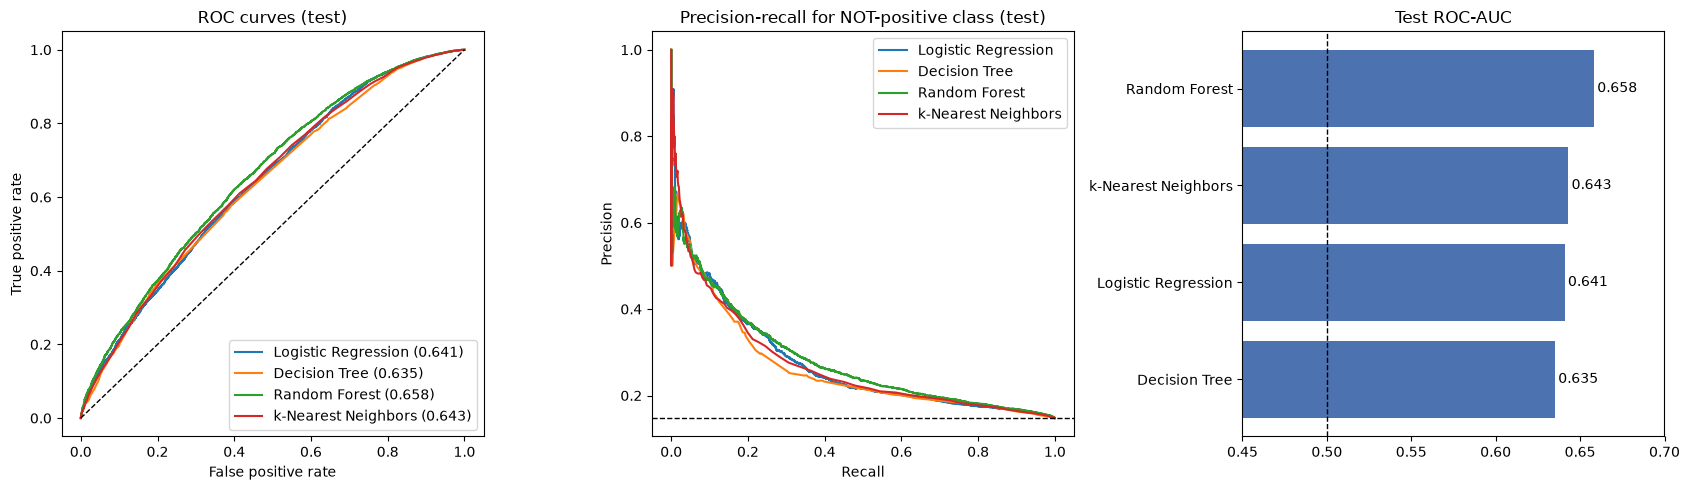

In [43]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax[0].plot(fpr, tpr, label=f"{name} ({roc_auc_score(y_te, p):.3f})")
    pr, rc, _ = precision_recall_curve(1 - y_te, 1 - p); ax[1].plot(rc, pr, label=name)
ax[0].plot([0, 1], [0, 1], "k--", lw=1); ax[0].set(title="ROC curves (test)", xlabel="False positive rate", ylabel="True positive rate"); ax[0].legend()
ax[1].axhline(1 - y_te.mean(), color="k", ls="--", lw=1)
ax[1].set(title="Precision-recall for NOT-positive class (test)", xlabel="Recall", ylabel="Precision"); ax[1].legend()

res = results_df["ROC-AUC"].sort_values()
ax[2].barh(res.index, res.values, color="#4C72B0"); ax[2].axvline(0.5, color="k", ls="--", lw=1)
ax[2].set(title="Test ROC-AUC", xlim=(0.45, max(0.7, res.max() + 0.03)))
for i, v in enumerate(res.values): ax[2].text(v + 0.002, i, f"{v:.3f}", va="center")
plt.tight_layout(); plt.show()

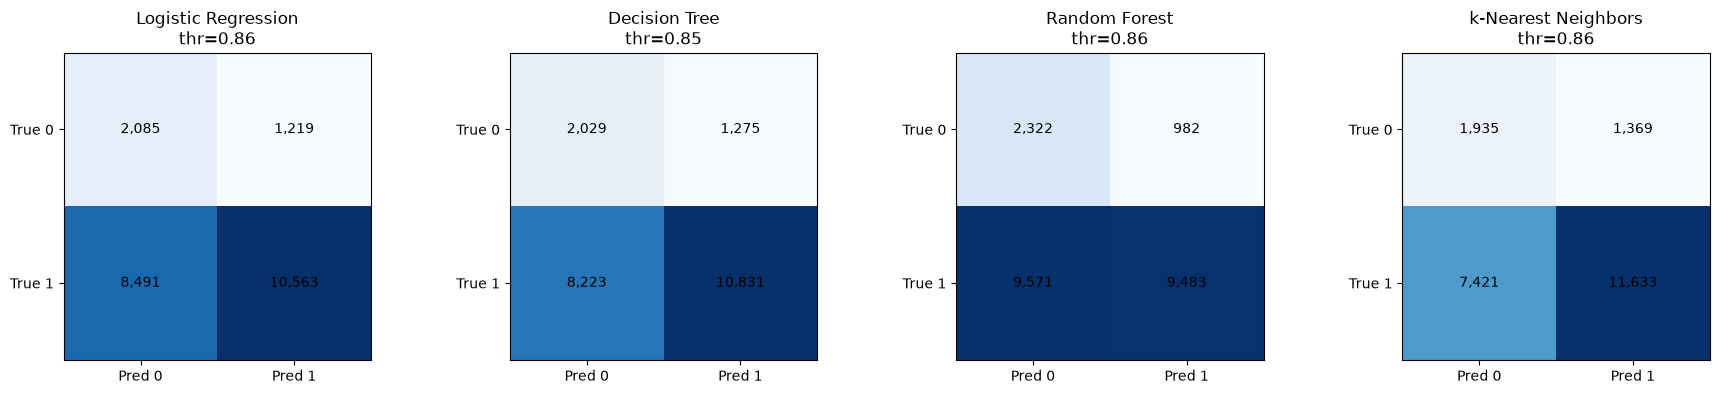

Best model by test ROC-AUC: Random Forest


In [44]:
best_name = results_df["ROC-AUC"].idxmax()
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (name, p) in zip(ax, probs.items()):
    cm = confusion_matrix(y_te, (p >= thresholds[name]).astype(int))
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]:,}", ha="center", va="center")
    a.set(title=f"{name}\nthr={thresholds[name]:.2f}", xticks=[0, 1], yticks=[0, 1],
          xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
plt.tight_layout(); plt.show()
print("Best model by test ROC-AUC:", best_name)

## What drives prediction?

**Feature-group ablation:** refit the tuned models using (a) book/metadata features only, (b) customer/book history only, and (c) everything.

In [45]:
sets = {"Metadata only": (META_NUM, META_CAT),
        "History only": (HIST_NUM, []),
        "All features": (META_NUM + HIST_NUM, META_CAT)}
ctors = {k: v[0] for k, v in grids.items()}
abl = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest"]:
    params = fitted[name][1]
    for sname, (nc, cc) in sets.items():
        pipe = Pipeline([("pre", make_preprocessor(nc, cc)), ("clf", ctors[name](**params))]).fit(tr[nc + cc], y_tr)
        abl.append({"Model": name, "Features": sname,
                    "Test ROC-AUC": roc_auc_score(y_te, pipe.predict_proba(te[nc + cc])[:, 1])})
abl_df = pd.DataFrame(abl).pivot(index="Model", columns="Features", values="Test ROC-AUC")[list(sets)].round(4)
abl_df

Features,Metadata only,History only,All features
Model,,,
Decision Tree,0.5742,0.6235,0.6351
Logistic Regression,0.5654,0.6257,0.6408
Random Forest,0.5869,0.6239,0.6582


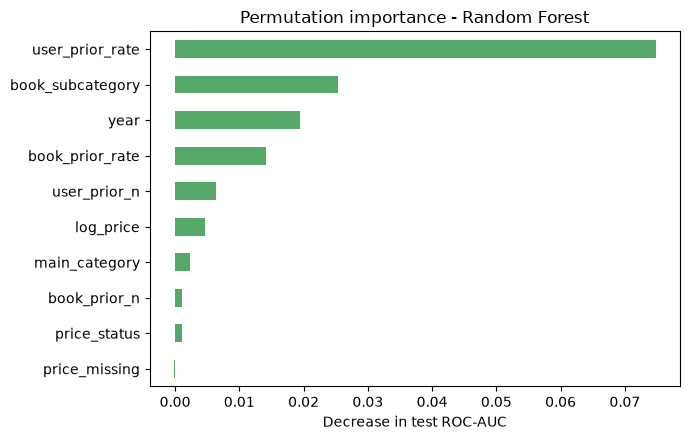

In [46]:
pipe = fitted[best_name][2]
pi = permutation_importance(pipe, te[ALL_FEATURES], y_te, scoring="roc_auc", n_repeats=5, random_state=RANDOM_STATE)
imp = pd.Series(pi.importances_mean, index=ALL_FEATURES).sort_values()
ax = imp.plot.barh(figsize=(7, 4.5), color="#55A868", title=f"Permutation importance - {best_name}")
ax.set_xlabel("Decrease in test ROC-AUC"); plt.tight_layout(); plt.show()

if best_name == "Logistic Regression":
    names = pipe.named_steps["pre"].get_feature_names_out()
    coef = pd.Series(pipe.named_steps["clf"].coef_[0], index=names).sort_values()
    display(pd.concat([coef.head(8), coef.tail(8)]).round(3).to_frame("coefficient"))

## Are the model differences real? And what about customers with no history?

Because prior customer ratings is by far our strongest predictor, does that mean that the model is not useful for customers without any prior ratings history? If so, what is the predictive performance difference between customers with history and without? Bootstrap 95% intervals for test ROC-AUC, plus performance split by whether the customer had any earlier review (**cold start** vs **has history**).

In [47]:
rng = np.random.default_rng(RANDOM_STATE)
B = 200
idx_all = [rng.integers(0, len(y_te), len(y_te)) for _ in range(B)]
boot = {}
for name, p in list(probs.items()) + [("Customer history rule", te["user_prior_rate"].values)]:
    aucs = [roc_auc_score(y_te[i], p[i]) for i in idx_all]
    boot[name] = (roc_auc_score(y_te, p), np.percentile(aucs, 2.5), np.percentile(aucs, 97.5))
boot_df = pd.DataFrame(boot, index=["ROC-AUC", "CI low", "CI high"]).T.round(4)
display(boot_df)


diff = [roc_auc_score(y_te[i], probs[best_name][i]) - roc_auc_score(y_te[i], te["user_prior_rate"].values[i]) for i in idx_all]
print(f"{best_name} minus customer-history rule: mean {np.mean(diff):+.4f}, 95% CI [{np.percentile(diff, 2.5):+.4f}, {np.percentile(diff, 97.5):+.4f}]")

,ROC-AUC,CI low,CI high
Logistic Regression,0.6408,0.6317,0.6525
Decision Tree,0.6351,0.6236,0.6470
Random Forest,0.6582,0.6481,0.6691
k-Nearest Neighbors,0.6430,0.6327,0.6544
Customer history rule,0.6108,0.6029,0.6198


Random Forest minus customer-history rule: mean +0.0477, 95% CI [+0.0398, +0.0564]


In [48]:
has_hist = (te["user_prior_n"].values > 0)
print(f"Test reviews from customers with prior history: {has_hist.mean():.1%}")
rows = []
for name, p in probs.items():
    for label, m in [("Cold start (no prior reviews)", ~has_hist), ("Has prior history", has_hist)]:
        rows.append({"Model": name, "Segment": label, "n": int(m.sum()),
                     "Positive rate": y_te[m].mean(), "ROC-AUC": roc_auc_score(y_te[m], p[m])})
pd.DataFrame(rows).pivot(index="Model", columns="Segment", values="ROC-AUC").round(4).join(
    pd.DataFrame(rows).groupby("Segment")[["n", "Positive rate"]].first().T.rename(index={"n": "n (segment size)"}), how="outer") if False else pd.DataFrame(rows).pivot(index="Model", columns="Segment", values="ROC-AUC").round(4)

Test reviews from customers with prior history: 38.8%


Segment,Cold start (no prior reviews),Has prior history
Model,,
Decision Tree,0.5624,0.7150
Logistic Regression,0.5701,0.7221
Random Forest,0.5985,0.7292
k-Nearest Neighbors,0.5893,0.7131


## Further Examination of the Logistic Regression Model

Because all of our models perform nearly identically, we can default to the most efficient model timewise and memory wise, the logistic regression.

Numeric features (per 1 standard deviation increase):


,feature,coefficient,odds_ratio
4,num__user_prior_rate,0.600,1.822
3,num__user_prior_n,0.147,1.158
6,num__book_prior_rate,0.126,1.135
2,num__year,0.049,1.050
5,num__book_prior_n,0.046,1.047
0,num__log_price,0.044,1.045
1,num__price_missing,-0.005,0.995


\nTop 10 categorical coefficients (push toward positive):


,feature,coefficient,odds_ratio
20,cat__book_subcategory_Christian Books & Bibles,0.393,1.481
19,cat__book_subcategory_Children's Books,0.345,1.413
40,cat__book_subcategory_Romance,0.174,1.190
28,cat__book_subcategory_History,0.167,1.182
14,cat__main_category_Buy a Kindle,0.164,1.179
39,cat__book_subcategory_Religion & Spirituality,0.162,1.176
43,cat__book_subcategory_Self-Help,0.157,1.170
49,cat__book_subcategory_infrequent_sklearn,0.114,1.121
17,cat__book_subcategory_Biographies & Memoirs,0.113,1.119
48,cat__book_subcategory_Unknown,0.089,1.093


\nBottom 10 categorical coefficients (push toward not-positive):


,feature,coefficient,odds_ratio
30,cat__book_subcategory_LGBTQ+ Books,-0.092,0.913
35,"cat__book_subcategory_New, Used & Rental Textb...",-0.115,0.891
18,cat__book_subcategory_Business & Money,-0.116,0.890
10,cat__price_status_unavailable_marker,-0.119,0.888
41,cat__book_subcategory_Science & Math,-0.135,0.874
32,cat__book_subcategory_Literature & Fiction,-0.142,0.867
42,cat__book_subcategory_Science Fiction & Fantasy,-0.171,0.843
12,cat__main_category_Audible Audiobooks,-0.177,0.838
34,"cat__book_subcategory_Mystery, Thriller & Susp...",-0.254,0.776
22,cat__book_subcategory_Computers & Technology,-0.374,0.688


\nPermutation importance (drop in test ROC-AUC):


,importance_mean,importance_std
user_prior_rate,0.0787,0.0026
book_subcategory,0.0258,0.0021
book_prior_rate,0.0165,0.0013
year,0.0030,0.0010
user_prior_n,0.0027,0.0007
log_price,0.0023,0.0005
book_prior_n,0.0008,0.0009
main_category,0.0006,0.0003
price_status,0.0004,0.0003
price_missing,-0.0002,0.0001


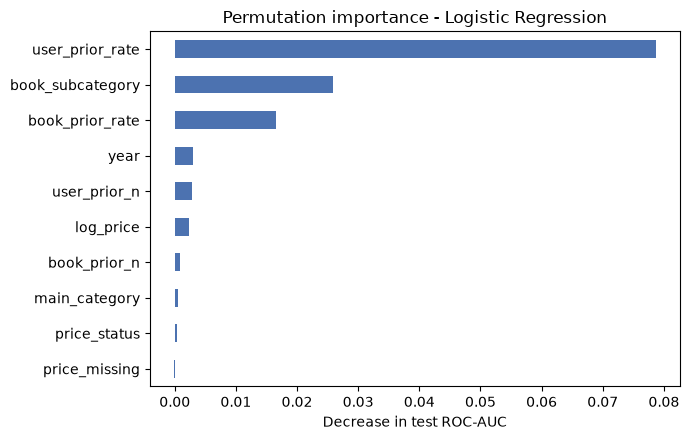

In [49]:

lr_pipe = fitted["Logistic Regression"][2]


names = lr_pipe.named_steps["pre"].get_feature_names_out()
coefs = lr_pipe.named_steps["clf"].coef_[0]

coef_df = pd.DataFrame({
    "feature": names,
    "coefficient": coefs,
    "odds_ratio": np.exp(coefs),
}).sort_values("coefficient", ascending=False)


num_df = coef_df[coef_df["feature"].str.startswith("num__")]
print("Numeric features (per 1 standard deviation increase):")
display(num_df.round(3))

print("\\nTop 10 categorical coefficients (push toward positive):")
display(coef_df[coef_df["feature"].str.startswith("cat__")].head(10).round(3))
print("\\nBottom 10 categorical coefficients (push toward not-positive):")
display(coef_df[coef_df["feature"].str.startswith("cat__")].tail(10).round(3))


pi_lr = permutation_importance(lr_pipe, te[ALL_FEATURES], y_te, scoring="roc_auc",
                               n_repeats=5, random_state=RANDOM_STATE)
imp_lr = pd.DataFrame({"importance_mean": pi_lr.importances_mean,
                       "importance_std": pi_lr.importances_std},
                      index=ALL_FEATURES).sort_values("importance_mean", ascending=False)
print("\\nPermutation importance (drop in test ROC-AUC):")
display(imp_lr.round(4))

imp_lr["importance_mean"].sort_values().plot.barh(
    figsize=(7, 4.5), color="#4C72B0", title="Permutation importance - Logistic Regression")
plt.xlabel("Decrease in test ROC-AUC"); plt.tight_layout(); plt.show()

## Conclusions

**Baselines.** Always predicting "positive" gives 84.8% test accuracy but ROC-AUC 0.50 and catches no unhappy ratings. A one-feature rule based on the customer's prior positive rate reaches ROC-AUC 0.697. However, this does not give any insight into which books customers will not prefer.

**Model comparison (test ROC-AUC, 95% bootstrap CI).** Random forest 0.702 [0.694, 0.711], decision tree 0.702 [0.694, 0.710], logistic regression 0.701 [0.693, 0.710], k-NN 0.701 [0.692, 0.710]. The intervals overlap almost completely, so **the four models are statistically indistinguishable**. Random forest beats the customer-history rule by only +0.005 (95% CI +0.000 to +0.011). Given the similar effectiveness of each model, we should choose to use the logistic regression as it is the simplest and easiest to work with.

**What predicts positive ratings.** Customer rating history is the dominant signal. Book metadata alone (price, category, subcategory, year) gives ROC-AUC of only about 0.53 to 0.55, history alone gives about 0.69 to 0.70, and combining them adds almost nothing. Specifically, the highest predictive signaal is the customer history of positive ratings. Customer's who have rated books highly in the past are much more likely to rate books highly in the future.

**Cold start.** About 65% of test reviews come from customers with prior reviews (ROC-AUC about 0.75). The remaining 35% have no history, and there performance falls to about 0.55 to 0.58, close to chance. k-NN and random forest are slightly better in the cold-start segment. This proportion of customers may stay steady or shrink as customers provide more reviews, and as new customers join the dataset.

**Recommendation.** Use logistic regression or a shallow decision tree as the working model: they perform as well as the more complex models and are easy to explain. To improve meaningfully, add richer signals (e.g., review text, book average rating, author history, gradient boosting) rather than tuning these four further.

**Limitations.** Data is a sample of Amazon reviews, so history is incomplete. Thresholds were tuned for balanced accuracy, and other thresholds suit other business costs. Results come from a single chronological split. Customer reviews are also a biased dataset because, much like survey results, they will only show behaviors related to people who are likely to submit reviews.